# Per-source performance by taxonomic rank

Per-point test dumps from `scripts/dump_point_predictions.py` (`results_tmp/<model>/test/`).

All analysis runs on a random subset of `N_SOURCES` test sources (drawn with `SEED`, the same subset for every model).

For each model and taxonomic rank, every sampled source is one point:
- **x**: one fixed source order for every subplot and every model: sources sorted by `SORT_BY` (default: order-rank accuracy,
  all annotations) of the first available model in `DUMPS`, lowest to highest. A source without enough points at a rank leaves a gap.
- **y**: the metric.
  - **Accuracy** is the eval's rank accuracy over points labelled at that rank, `none` included.
  - **Macro F1** is the mean F1 over taxa within the source.
- **Marker size**: number of images in the source. Area grows with √images.
- **Marker shape**: number of distinct annotated taxa at that rank in the source, `none` included, binned.
- **Color**: blue = all annotations; orange = the same metric with every point annotated `none` at that rank removed
  (accuracy over the remaining points = the eval's `acc_living`; macro F1 over those points, without the `none` taxon).
  A thin line joins a source's two values.

A source with fewer than `MIN_POINTS` points labelled at a rank (or, for orange, fewer than `MIN_POINTS` non-`none` points) has
that value left out; the counts are in each subplot title.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

REPO = Path("../..").resolve()
sys.path.insert(0, str(REPO))
from mermaidseg.evaluation.point_dump import PointDump, summary_by, taxon_metrics

SEED = 0
N_SOURCES = 20        # random subset of test sources used for all analysis below
LABEL_SOURCES = True  # source ids as x tick labels (else rank numbers)

DUMPS = {  # label -> dump directory
    "cbm_final_res256 step300k (256 px)": REPO / "results_tmp/cbm_final_res256_step300000/test",
    "cbm_cd275000_res768 step50k (768 px)": REPO / "results_tmp/cbm_cd275000_res768_step50000/test",
    "cbm_final_res768 step50k (768 px)": REPO / "results_tmp/cbm_final_res768_step50000/test",
}
SORT_BY = ("order", "accuracy")  # (rank, metric column) that fixes the source order of every plot
MIN_POINTS = 30       # min points labelled at a rank for a source to be plotted at that rank
F1_TAXA = "union"     # "union": taxa annotated or predicted in the source (sklearn macro); "gt": annotated taxa only
TAXA_BINS = [(1, 1), (2, 3), (4, 6), (7, 10), (11, 20), (21, 10_000)]   # distinct-taxa ranges -> markers
MARKERS = ["o", "s", "^", "D", "P", "*"]
SIZE_REF = [25, 100, 1_000, 9_000]   # images, for the size legend
SERIES = {"all": ("All annotations", "#2a78d6"), "nonone": ("`none` removed", "#eb6834")}  # validated categorical slots 1-2

COLOR = "#2a78d6"; INK = "#0b0b0b"; INK2 = "#52514e"; GRID = "#e4e3df"; SURFACE = "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

ACTIVE_MODELS = ["cbm_final_res256 step300k (256 px)"]  # models analysed below; add the 768 key to include it

dumps = {}
for name, path in DUMPS.items():
    if name not in ACTIVE_MODELS:
        continue
    if (path / "points.parquet").exists():
        dumps[name] = PointDump.load(path)
        print(f"{name}: {len(dumps[name].df):,} points")
    else:
        print(f"{name}: not available yet ({path})")

# Same random subset of test sources for every model.
all_sources = sorted(set.intersection(*(set(d.meta["sources"]) for d in dumps.values())))
rng = np.random.default_rng(SEED)
SOURCES = sorted(rng.choice(all_sources, size=N_SOURCES, replace=False).tolist())
for d in dumps.values():
    d.df = d.df[d.df.source_id.isin(SOURCES)].reset_index(drop=True)
    d.images = d.images[d.images.source_id.isin(SOURCES)].reset_index(drop=True)
print(f"{N_SOURCES} of {len(all_sources)} test sources (seed {SEED}):", SOURCES)

cbm_final_res256 step300k (256 px): 1,511,187 points
20 of 144 test sources (seed 0): [546, 1304, 1776, 2682, 3406, 3765, 4710, 4811, 5024, 5100, 5130, 5227, 5325, 5494, 5699, 5796, 6693, 7085, 7614, 7663]


In [2]:
def per_source_rank_table(d: PointDump) -> pd.DataFrame:
    """One row per (rank, source): accuracy and macro F1 with all annotations and with `none` removed."""
    df = d.df
    n_images = d.images.groupby("source_id").size().rename("n_images")
    summ = summary_by(df, "source_id").set_index("source_id")
    rows = []
    for rank in d.ranks:
        def macro_f1(tm):
            if F1_TAXA == "gt":
                tm = tm[tm.n_gt > 0]
            return tm.groupby("source_id").f1.mean()
        tm = taxon_metrics(df, rank, by="source_id")
        tm_nn = taxon_metrics(df[df[f"gt_{rank}"].astype(str) != "none"], rank, by="source_id")
        tm_nn = tm_nn[tm_nn.taxon.astype(str) != "none"]
        t = pd.DataFrame({
            "macro_f1": macro_f1(tm),
            "macro_f1_nonone": macro_f1(tm_nn),
            "n_taxa": tm[tm.n_gt > 0].groupby("source_id").size(),
            "n_points": tm.groupby("source_id").n_gt.sum(),
        })
        t["accuracy"] = summ[f"{rank}_acc_all"]
        t["accuracy_nonone"] = summ[f"{rank}_acc_living"]
        t["n_points_nonone"] = summ[f"{rank}_n_living"]
        t = t.join(n_images).assign(rank=rank).reset_index()
        rows.append(t)
    return pd.concat(rows, ignore_index=True)

tables = {name: per_source_rank_table(d) for name, d in dumps.items()}
# One source order for all plots: SORT_BY of the first available model; sources lacking it go first.
_ref = next(iter(tables.values()))
_key = _ref[(_ref["rank"] == SORT_BY[0]) & (_ref.n_points >= MIN_POINTS)].set_index("source_id")[SORT_BY[1]]
SOURCE_ORDER = _key.reindex(SOURCES).sort_values(na_position="first").index.tolist()
print("source order:", SOURCE_ORDER)
_ref.head()

source order: [3765, 7663, 4710, 7614, 546, 5796, 1776, 2682, 5130, 5325, 5699, 1304, 6693, 5100, 3406, 5024, 4811, 5227, 7085, 5494]


,source_id,macro_f1,macro_f1_nonone,n_taxa,n_points,accuracy,accuracy_nonone,n_points_nonone,n_images,rank
0,546,0.399414,0.428595,3,3315,0.647059,0.814661,723,78,kingdom
1,1304,0.334318,0.210702,2,1931,0.838426,0.728324,519,111,kingdom
2,1776,0.477378,0.405828,4,13271,0.765579,0.667572,5890,447,kingdom
3,2682,0.582060,0.578013,3,16760,0.839916,0.777246,4597,675,kingdom
4,3406,0.715203,0.665815,3,1375,0.852364,0.776786,672,62,kingdom


In [3]:
def marker_for(n_taxa: int) -> str:
    for (lo, hi), m in zip(TAXA_BINS, MARKERS):
        if lo <= n_taxa <= hi:
            return m
    return MARKERS[-1]

def area(n_images):
    return 15 + 4 * np.sqrt(np.asarray(n_images, float))   # pt^2, area ~ sqrt(images)

def bin_label(lo, hi):
    return f"{lo}" if lo == hi else (f"{lo}+" if hi >= 10_000 else f"{lo}–{hi}")

def plot_model(name: str, t: pd.DataFrame, ranks: list[str]):
    metrics = [("accuracy", "Accuracy"), ("macro_f1", "Macro F1")]
    fig, axes = plt.subplots(len(ranks), 2, figsize=(14, 3.4 * len(ranks)), sharey=True)
    for i, rank in enumerate(ranks):
        r = t[(t["rank"] == rank) & (t.n_points >= MIN_POINTS)]
        n_dropped = int(((t["rank"] == rank) & (t.n_points < MIN_POINTS)).sum())
        for j, (col, label) in enumerate(metrics):
            ax = axes[i, j]
            s = r.set_index("source_id").reindex(SOURCE_ORDER).rename_axis("source_id").reset_index()
            x = np.arange(1, len(s) + 1)
            y_all = s[col].to_numpy(dtype=float)
            y_nn = np.where(s.n_points_nonone >= MIN_POINTS, s[f"{col}_nonone"], np.nan).astype(float)
            n_all, n_nn = int(np.isfinite(y_all).sum()), int(np.isfinite(y_nn).sum())
            ax.vlines(x, np.fmin(y_all, y_nn), np.fmax(y_all, y_nn), color=GRID, lw=1.5, zorder=2)
            for key, y in (("all", y_all), ("nonone", y_nn)):
                color = SERIES[key][1]
                for m in MARKERS:
                    sel = (s.n_taxa.fillna(1).map(marker_for) == m).to_numpy() & np.isfinite(y)
                    ax.scatter(x[sel], y[sel], s=area(s.loc[sel, "n_images"]), marker=m,
                               facecolors="none", edgecolors=color, linewidths=1.4, zorder=3)
                med = np.nanmedian(y)
                ax.axhline(med, color=color, lw=1, ls="--", alpha=0.8, zorder=1)
            ax.set_xticks(x)
            if LABEL_SOURCES:
                ax.set_xticklabels(s.source_id.astype(str), rotation=90, fontsize=8)
            ax.set_ylim(-0.03, 1.05)
            ax.set_xlim(0.3, len(s) + 0.7)
            if rank == SORT_BY[0] and col == SORT_BY[1]:
                ax.set_facecolor("#f0efec")  # the subplot that defines the order
            ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
            title = (f"{rank} — {label}   median {np.nanmedian(y_all):.2f} (all) / {np.nanmedian(y_nn):.2f} (none removed)"
                     f"   n={n_all}" + (f" / {n_nn}" if n_nn != n_all else "") + " sources")
            ax.set_title(title, fontsize=9.5, loc="left", color=INK)
            if i == len(ranks) - 1:
                ax.set_xlabel(f"Sources, sorted by {SORT_BY[0]} {SORT_BY[1]} (all annotations, lowest → highest)")
            if j == 0:
                ax.set_ylabel(label if i == 0 else "")
    series_handles = [Line2D([], [], marker="o", ls="--", lw=1, color=c, markerfacecolor="none", markeredgewidth=1.4,
                             markersize=9, label=f"{lab} (dashed = median)") for lab, c in SERIES.values()]
    shape_handles = [Line2D([], [], marker=m, ls="", markerfacecolor="none", markeredgecolor=INK2, markeredgewidth=1.3,
                            markersize=9, label=bin_label(lo, hi)) for (lo, hi), m in zip(TAXA_BINS, MARKERS)]
    size_handles = [plt.scatter([], [], s=area(n), facecolors="none", edgecolors=INK2, linewidths=1.3, label=f"{n:,}")
                    for n in SIZE_REF]
    fig.legend(handles=series_handles, loc="upper left", bbox_to_anchor=(0.06, 1.0), ncol=1, frameon=False)
    fig.legend(handles=shape_handles, title="Distinct annotated taxa at rank (incl. none)", loc="upper center",
               bbox_to_anchor=(0.5, 1.0), ncol=len(MARKERS), frameon=False)
    fig.legend(handles=size_handles, title="Images in source", loc="upper right",
               bbox_to_anchor=(0.98, 1.0), ncol=len(SIZE_REF), frameon=False, scatterpoints=1)
    fig.suptitle(name, x=0.06, y=1.035, ha="left", fontsize=13, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.965))
    return fig

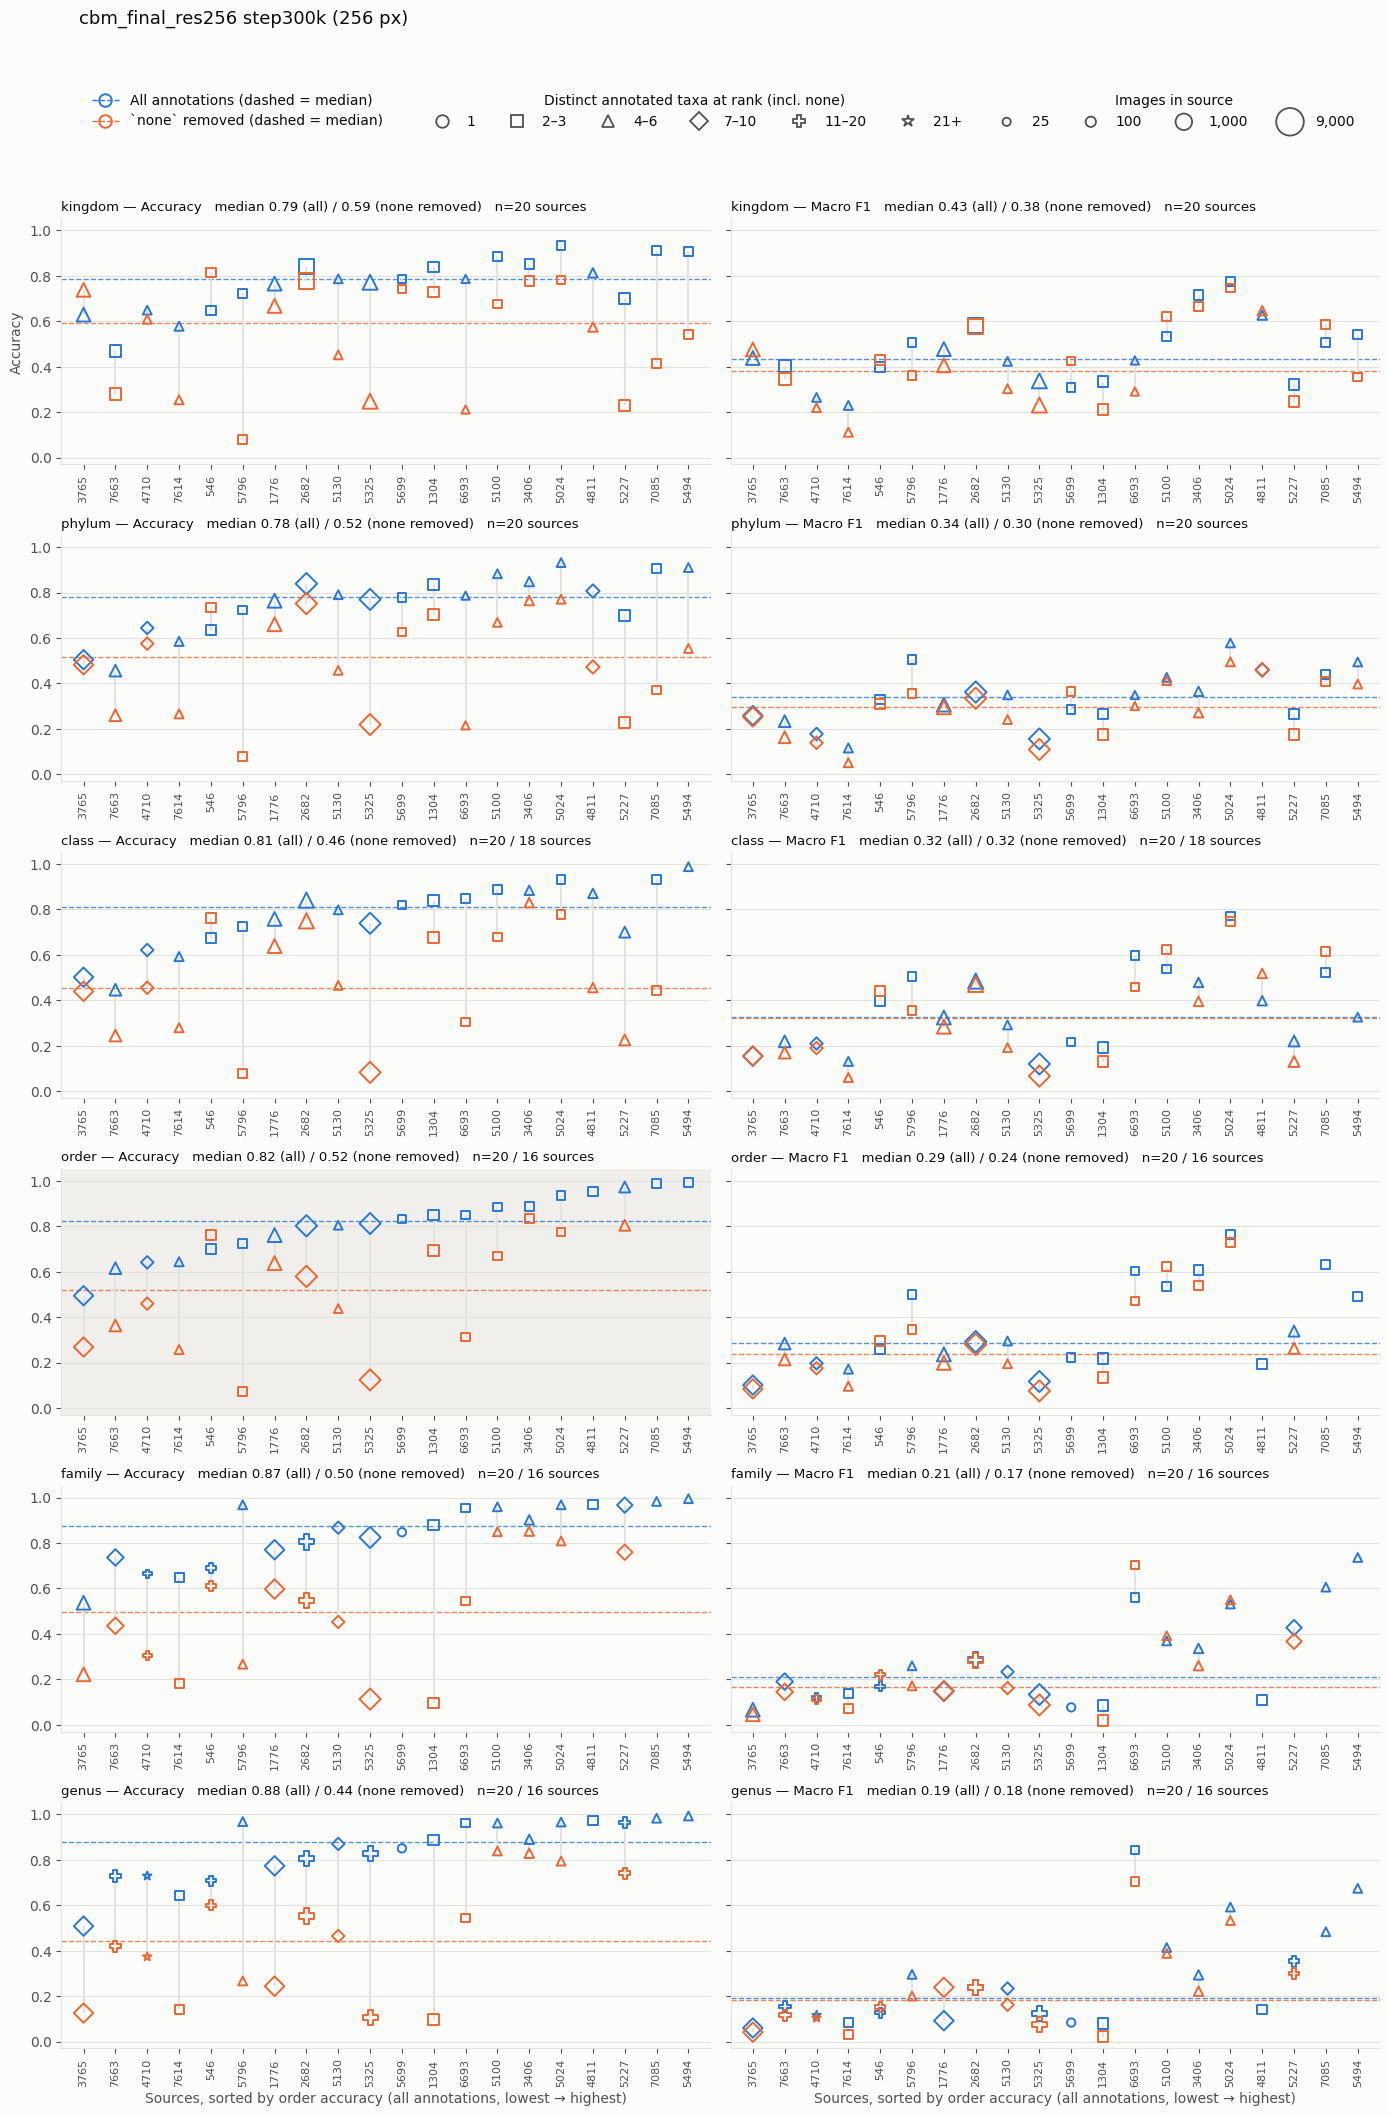

In [4]:
for name, t in tables.items():
    fig = plot_model(name, t, dumps[name].ranks)
    plt.show()

Per-source table behind the plots (one row per model, rank and source).

In [5]:
all_t = pd.concat([t.assign(model=name) for name, t in tables.items()], ignore_index=True)
all_t.sort_values(["model", "rank", "accuracy"]).round(3)

,source_id,macro_f1,macro_f1_nonone,n_taxa,n_points,accuracy,accuracy_nonone,n_points_nonone,n_images,rank,model
59,7663,0.219,0.170,5,4966,0.446,0.245,3559,200,class,cbm_final_res256 step300k (256 px)
45,3765,0.154,0.155,7,9512,0.502,0.439,4875,427,class,cbm_final_res256 step300k (256 px)
58,7614,0.131,0.060,4,807,0.592,0.279,412,48,class,cbm_final_res256 step300k (256 px)
46,4710,0.209,0.190,7,2225,0.621,0.455,624,41,class,cbm_final_res256 step300k (256 px)
40,546,0.395,0.441,3,3271,0.673,0.763,679,78,class,cbm_final_res256 step300k (256 px)
...,...,...,...,...,...,...,...,...,...,...,...
24,3406,0.365,0.271,5,1375,0.849,0.765,672,62,phylum,cbm_final_res256 step300k (256 px)
29,5100,0.427,0.413,4,470,0.883,0.669,145,40,phylum,cbm_final_res256 step300k (256 px)
37,7085,0.438,0.407,3,513,0.906,0.371,70,40,phylum,cbm_final_res256 step300k (256 px)
33,5494,0.495,0.397,5,480,0.910,0.554,83,40,phylum,cbm_final_res256 step300k (256 px)


# Kingdom: per-value analysis

Taxon-level view of the kingdom head on the same 20 sources: what the true kingdom values get predicted as, how each
value does in each source, and which raw CoralNet labels the errors come from. `none` at kingdom = non-living / no
organism, as encoded in the concept table.

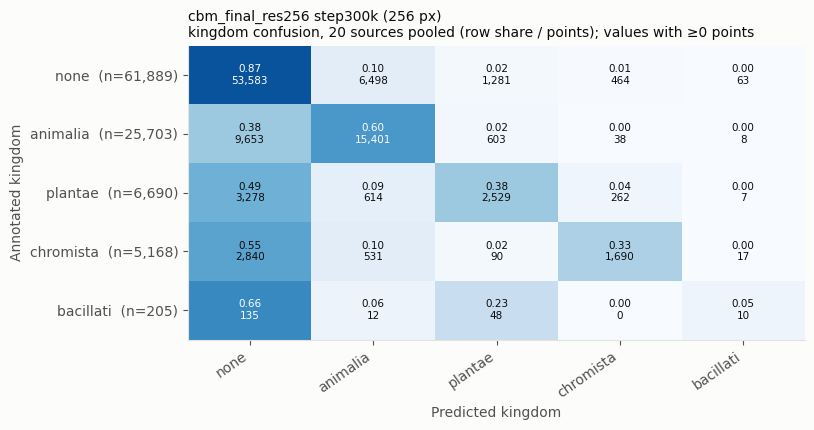

In [6]:
RANK = "kingdom"
MIN_GT = 30   # min annotated points of a value in a source to show it
VALUES_COLOR = {"recall": "#2a78d6", "precision": "#eb6834"}

def rank_frame(d: PointDump, rank: str = RANK) -> pd.DataFrame:
    k = d.df[d.df[f"gt_{rank}"].notna()].copy()
    k["y_true"] = k[f"gt_{rank}"].astype(str)
    k["y_pred"] = k[f"pred_{rank}"].astype(str)
    return k

def plot_confusion(name: str, k: pd.DataFrame, rank: str = RANK, min_n: int = 0, top: int | None = None):
    """Row-normalised confusion of annotated vs predicted values. Rows: annotated values with >= min_n points
    (at most `top`, most frequent first). Columns: the same values, then "other" for any other prediction."""
    vc = k.y_true.value_counts()
    vals = list(vc[vc >= min_n].index)[:top]
    k = k[k.y_true.isin(vals)]
    pred = k.y_pred.where(k.y_pred.isin(vals), "other")
    cols = vals + (["other"] if (pred == "other").any() else [])
    ct = pd.crosstab(k.y_true, pred).reindex(index=vals, columns=cols, fill_value=0)
    frac = ct.div(ct.sum(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(1.05 * len(cols) + 3, 0.5 * len(ct) + 1.9))
    ax.imshow(frac.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(frac.shape[0]):
        for j in range(frac.shape[1]):
            v = frac.iat[i, j]
            ax.text(j, i, f"{v:.2f}\n{ct.iat[i, j]:,}", ha="center", va="center", fontsize=7.5,
                    color="white" if v > 0.55 else INK)
    ax.set_xticks(range(len(cols)), cols, rotation=35, ha="right")
    ax.set_yticks(range(len(ct)), [f"{v}  (n={ct.loc[v].sum():,})" for v in ct.index])
    ax.set_xlabel(f"Predicted {rank}"); ax.set_ylabel(f"Annotated {rank}")
    sel = f"values with ≥{min_n} points" + (f", top {top}" if top else "")
    ax.set_title(f"{name}\n{rank} confusion, {N_SOURCES} sources pooled (row share / points); {sel}", loc="left", fontsize=10)
    ax.grid(False)
    fig.tight_layout()
    return fig

for name, d in dumps.items():
    plot_confusion(name, rank_frame(d)); plt.show()

### Each kingdom value across sources
One panel per annotated value; sources in `SOURCE_ORDER` (same as above). Recall (blue) and precision (orange) of that
value within each source; marker area ~ √(annotated points of the value). Values with fewer than `MIN_GT` points in a
source are left out there; a value is shown if at least one source has `MIN_GT` points of it.

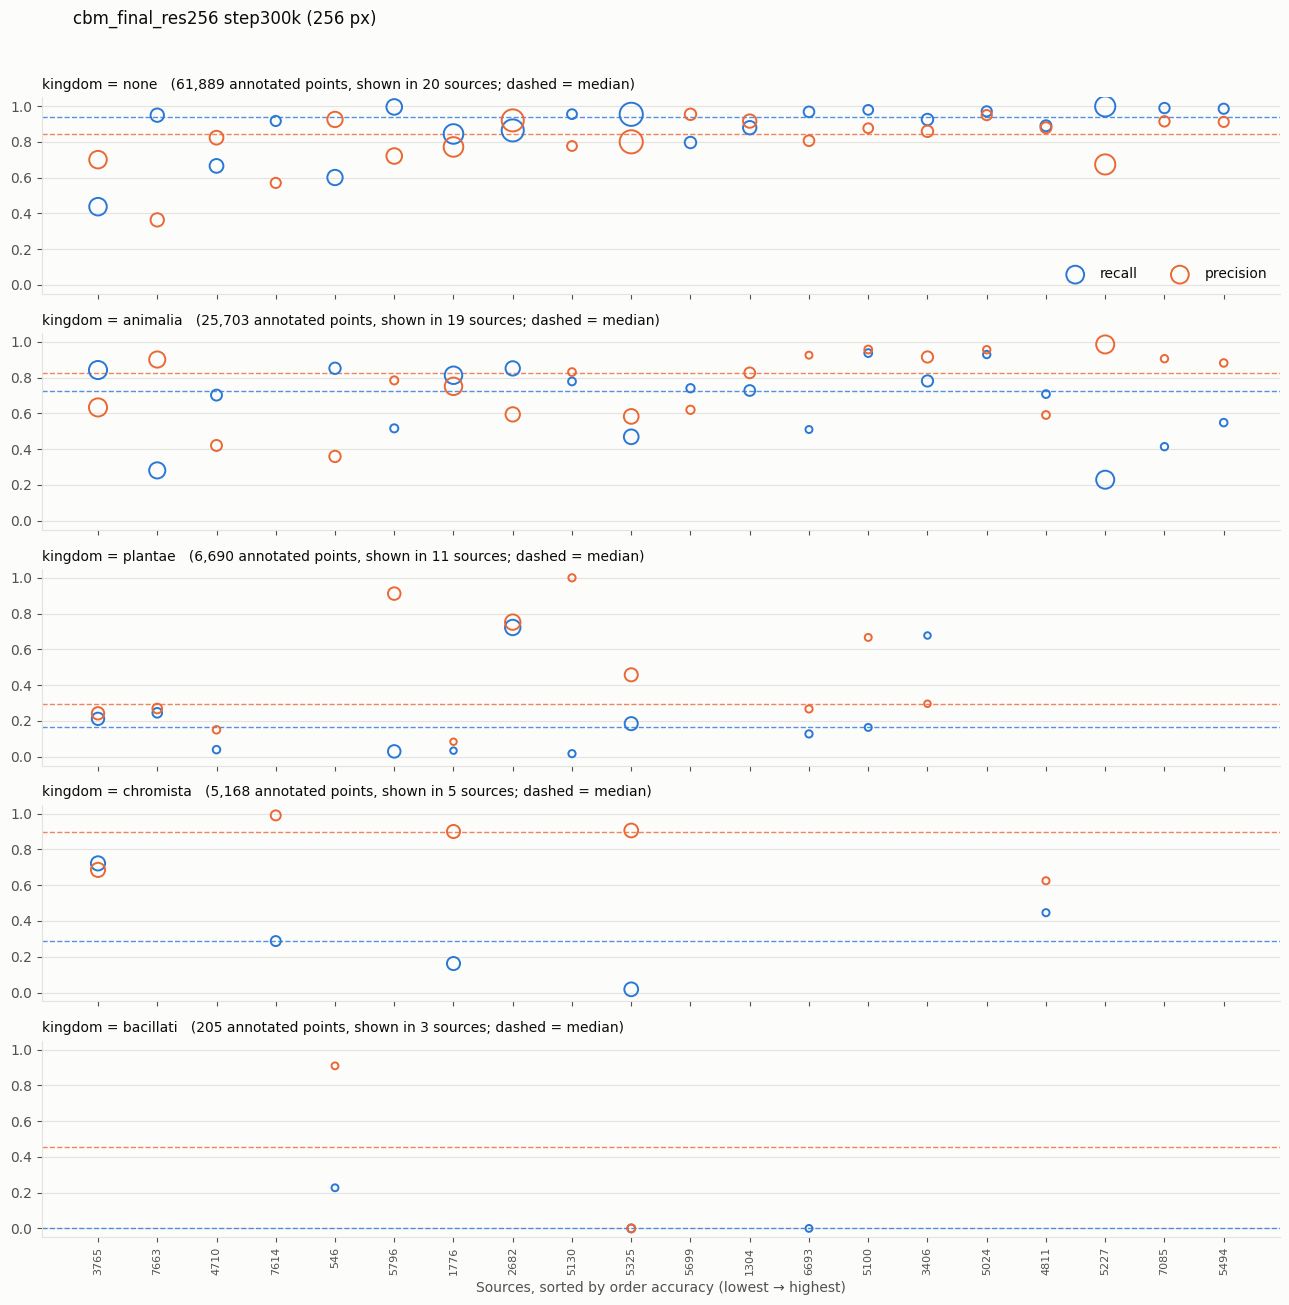

In [7]:
COND_COLOR = "#1baf7a"  # categorical slot 3

def plot_values_across_sources(name: str, d: PointDump, rank: str = RANK, parent: str | None = None,
                               max_values: int | None = None):
    """Recall / precision of each value of `rank` per source; with `parent`, also recall on points whose
    parent rank is predicted correctly (green)."""
    tm = taxon_metrics(d.df, rank, by="source_id")
    if parent is not None:
        pk = rank_frame(d, rank)
        pk = pk[pk[f"gt_{parent}"].notna() & (pk[f"gt_{parent}"].astype(str) == pk[f"pred_{parent}"].astype(str))]
        cond = (pk.assign(ok=pk.y_true == pk.y_pred).groupby(["y_true", "source_id"]).ok.agg(["mean", "size"]))
    vals = tm.groupby("taxon", observed=True).n_gt.sum().sort_values(ascending=False)
    vals = [v for v in vals.index.astype(str) if (tm[(tm.taxon.astype(str) == v) & (tm.n_gt >= MIN_GT)].shape[0] >= 1)][:max_values]
    fig, axes = plt.subplots(len(vals), 1, figsize=(13, 2.6 * len(vals)), sharex=True)
    axes = np.atleast_1d(axes)
    x = np.arange(1, len(SOURCE_ORDER) + 1)
    for ax, v in zip(axes, vals):
        t = tm[tm.taxon.astype(str) == v].set_index("source_id").reindex(SOURCE_ORDER)
        ok = (t.n_gt >= MIN_GT).to_numpy()
        for col, c in VALUES_COLOR.items():
            y = np.where(ok, t[col], np.nan)
            ax.scatter(x, y, s=10 + 2.2 * np.sqrt(t.n_gt.fillna(0)), facecolors="none", edgecolors=c, linewidths=1.4, zorder=3,
                       label=col)
            ax.axhline(np.nanmedian(y), color=c, lw=1, ls="--", alpha=0.8)
        if parent is not None and v in cond.index.get_level_values(0):
            cv = cond.loc[v].reindex(SOURCE_ORDER)
            y = np.where(cv["size"] >= MIN_GT, cv["mean"], np.nan)
            ax.scatter(x, y, s=10 + 2.2 * np.sqrt(cv["size"].fillna(0)), marker="D", facecolors="none",
                       edgecolors=COND_COLOR, linewidths=1.4, zorder=4, label=f"recall | {parent} correct")
            if np.isfinite(y).any():
                ax.axhline(np.nanmedian(y), color=COND_COLOR, lw=1, ls="--", alpha=0.8)
        ax.set_ylim(-0.05, 1.05); ax.grid(axis="y", color=GRID, lw=0.8)
        n_tot = int(t.n_gt.sum())
        ax.set_title(f"{rank} = {v}   ({n_tot:,} annotated points, shown in {ok.sum()} sources; dashed = median)",
                     loc="left", fontsize=10)
    axes[-1].set_xticks(x, [str(s) for s in SOURCE_ORDER], rotation=90, fontsize=8)
    axes[-1].set_xlabel(f"Sources, sorted by {SORT_BY[0]} {SORT_BY[1]} (lowest → highest)")
    axes[0].legend(loc="lower right", frameon=False, ncol=3)
    fig.suptitle(name, x=0.06, y=1.0, ha="left", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    return fig

for name, d in dumps.items():
    plot_values_across_sources(name, d); plt.show()

### Which raw labels the errors come from
For each annotated kingdom value: the CoralNet labels with the most wrong predictions, their recall, the share predicted
`none`, how many of the 20 sources use the label, and the label's MERMAID class (`gt_mermaid`) next to the class head's
most common prediction.

In [8]:
def label_errors(k: pd.DataFrame, value: str, top: int = 12) -> pd.DataFrame:
    x = k[k.y_true == value]
    g = x.groupby("source_label_name", observed=True)
    t = pd.DataFrame({
        "n": g.size(),
        "errors": g.apply(lambda s: (s.y_pred != value).sum()),
        "recall": g.apply(lambda s: (s.y_pred == value).mean()),
        "pred_none": g.apply(lambda s: (s.y_pred == "none").mean()),
        "top_pred": g.y_pred.agg(lambda s: s.mode().iloc[0]),
        "n_sources": g.source_id.nunique(),
        "gt_mermaid": g.gt_mermaid.agg(lambda s: s.astype(str).mode().iloc[0]),
        "pred_mermaid": g.pred_mermaid.agg(lambda s: s.astype(str).mode().iloc[0]),
    })
    t["share_of_value_errors"] = t.errors / max(t.errors.sum(), 1)
    return t.sort_values("errors", ascending=False).head(top).round(2)

name0, d0 = next(iter(dumps.items()))
k0 = rank_frame(d0)
for v in k0.y_true.value_counts().index:
    if (k0.y_true == v).sum() >= 200:
        print(f"\n{name0} — annotated {RANK} = {v}")
        display(label_errors(k0, v))


cbm_final_res256 step300k (256 px) — annotated kingdom = none


/tmp/ipykernel_1225449/3128475359.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "errors": g.apply(lambda s: (s.y_pred != value).sum()),
/tmp/ipykernel_1225449/3128475359.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "recall": g.apply(lambda s: (s.y_pred == value).mean()),
/tmp/ipykernel_1225449/3128475359.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprec

,n,errors,recall,pred_none,top_pred,n_sources,gt_mermaid,pred_mermaid,share_of_value_errors
source_label_name,,,,,,,,,
turf algae,23783,2525,0.89,0.89,none,12,turf algae,turf algae,0.30
long sediment-laden algal turf,4253,2337,0.45,0.45,none,1,nan,turf algae,0.28
all other,2485,1169,0.53,0.53,none,5,nan,turf algae,0.14
unknown,1148,404,0.65,0.65,none,8,nan,turf algae,0.05
pavement,940,394,0.58,0.58,none,1,bare substrate,bare substrate,0.05
quadrat,1135,334,0.71,0.71,none,1,transect tools,transect tools,0.04
sand,16828,188,0.99,0.99,none,17,sand,sand,0.02
biofilm,199,150,0.25,0.25,animalia,1,nan,bare substrate,0.02
tape,3033,115,0.96,0.96,none,3,transect tools,transect tools,0.01



cbm_final_res256 step300k (256 px) — annotated kingdom = animalia


/tmp/ipykernel_1225449/3128475359.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "errors": g.apply(lambda s: (s.y_pred != value).sum()),
/tmp/ipykernel_1225449/3128475359.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "recall": g.apply(lambda s: (s.y_pred == value).mean()),
/tmp/ipykernel_1225449/3128475359.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprec

,n,errors,recall,pred_none,top_pred,n_sources,gt_mermaid,pred_mermaid,share_of_value_errors
source_label_name,,,,,,,,,
dead coral,5692,5347,0.06,0.92,none,8,bare substrate,bare substrate,0.52
cred-octocoral,1720,1010,0.41,0.57,none,1,nan,turf algae,0.10
dead coral with algae,818,719,0.12,0.77,none,3,bare substrate,turf algae,0.07
ascidian (colonial),1405,363,0.74,0.16,animalia,1,nan,bare substrate,0.04
soft coral,849,261,0.69,0.31,animalia,4,soft coral,soft coral,0.03
worms: polychaetes,465,217,0.53,0.37,animalia,1,nan,bare substrate,0.02
bryozoan,3027,181,0.94,0.03,animalia,2,nan,bare substrate,0.02
porites compressa,1290,166,0.87,0.13,animalia,2,porites,porites,0.02
montipora capitata,896,164,0.82,0.18,animalia,3,montipora,montipora,0.02


... (5 outputs left out)

,n,errors,recall,pred_none,top_pred,n_sources,gt_mermaid,pred_mermaid,share_of_value_errors
source_label_name,,,,,,,,,
padina,2689,2329,0.13,0.79,none,4,padina,turf algae,0.67
sargassum,1435,527,0.63,0.19,chromista,3,sargassum,macroalgae,0.15
dictyota,391,277,0.29,0.53,none,3,dictyota,macroalgae,0.08
lobophora,300,108,0.64,0.08,chromista,2,lobophora,dictyota,0.03
brown macroalgae,110,107,0.03,0.87,none,1,nan,turf algae,0.03
ecklonia radiata,163,74,0.55,0.36,chromista,1,nan,macroalgae,0.02
"brown algae, unidentified",51,27,0.47,0.53,none,1,macroalgae,turf algae,0.01
turbinaria (algae),18,18,0.00,0.89,none,1,turbinaria-algae,turf algae,0.01
dictyota spp,11,11,0.00,1.00,none,1,nan,bare substrate,0.00



cbm_final_res256 step300k (256 px) — annotated kingdom = bacillati


/tmp/ipykernel_1225449/3128475359.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "errors": g.apply(lambda s: (s.y_pred != value).sum()),
/tmp/ipykernel_1225449/3128475359.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "recall": g.apply(lambda s: (s.y_pred == value).mean()),
/tmp/ipykernel_1225449/3128475359.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprec

,n,errors,recall,pred_none,top_pred,n_sources,gt_mermaid,pred_mermaid,share_of_value_errors
source_label_name,,,,,,,,,
cyanobacteria,155,155,0.00,0.68,none,4,cyanobacteria,turf algae,0.79
cyanobacteria films,44,34,0.23,0.59,none,1,cyanobacteria,turf algae,0.17
cyanobacteria_filamentous,6,6,0.00,0.67,none,1,cyanobacteria,turf algae,0.03


### Error attribution by label group
Groups defined from each point's concept row, so they follow the concept table rather than label names:
- **dead coral**: annotated `animalia` with `live` = False (dead coral, dead coral with algae, …)
- **turf**: annotated `none` with `algae` = True (turf algae, sediment-laden turf, …)
- **ambiguous**: annotated `none` with a catch-all label (unknown / all other / unclear / unidentified)
- **other algae**: annotated `plantae` or `chromista`
- **live animals**: the remaining `animalia`
- **other none**: the remaining `none` (sand, rock, pavement, transect tools, …)

In [9]:
AMBIGUOUS_RE = r"unknown|all other|unclear|^other$|unid"

def kingdom_groups(k: pd.DataFrame) -> pd.Series:
    lab = k.source_label_name.astype(str)
    live_false = k["gt__live"] == 1 if "gt__live" in k else False
    algae_true = k["gt__algae"] == 2 if "gt__algae" in k else False
    return pd.Series(np.select(
        [(k.y_true == "animalia") & live_false,
         (k.y_true == "none") & algae_true,
         (k.y_true == "none") & lab.str.contains(AMBIGUOUS_RE, regex=True),
         k.y_true.isin(["plantae", "chromista"]),
         k.y_true == "animalia"],
        ["dead coral", "turf", "ambiguous", "other algae", "live animals"], "other none"), index=k.index)

for name, d in dumps.items():
    k = rank_frame(d)
    k["group"] = kingdom_groups(k); k["err"] = k.y_true != k.y_pred
    t = k.groupby("group").agg(n=("err", "size"), errors=("err", "sum"), accuracy=("err", lambda e: 1 - e.mean()),
                               pred_none=("y_pred", lambda s: (s == "none").mean()))
    t["share_of_errors"] = t.errors / k.err.sum()
    print(f"\n{name}: kingdom accuracy {1 - k.err.mean():.3f}; "
          f"without dead coral + ambiguous {1 - k[~k.group.isin(['dead coral', 'ambiguous'])].err.mean():.3f}")
    display(t.sort_values("errors", ascending=False).round(3))


cbm_final_res256 step300k (256 px): kingdom accuracy 0.735; without dead coral + ambiguous 0.790


,n,errors,accuracy,pred_none,share_of_errors
group,,,,,
other algae,11858,7639,0.356,0.516,0.289
dead coral,6529,6081,0.069,0.901,0.230
turf,28777,4970,0.827,0.827,0.188
live animals,19174,4221,0.780,0.197,0.160
other none,29565,1954,0.934,0.938,0.074
ambiguous,3752,1577,0.580,0.580,0.060


Animalia recall per source, with and without dead coral: sources with a lot of dead coral look like the model misses
animals, but on live animals they are in line with the rest.

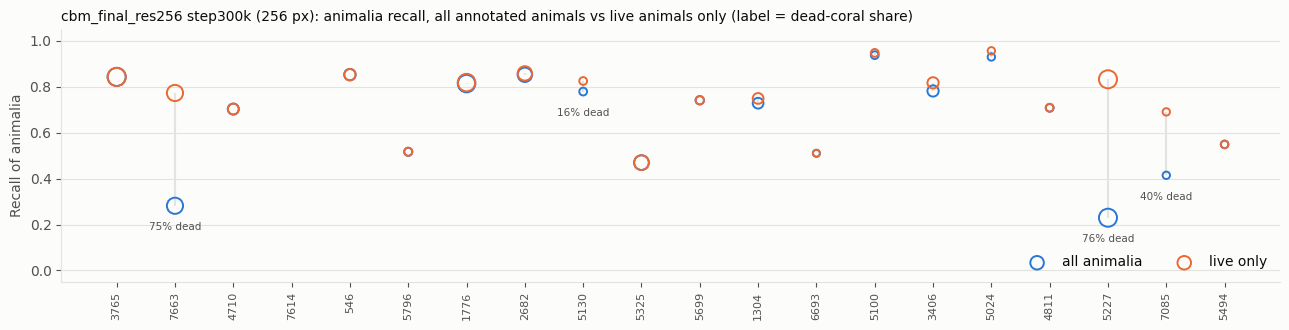

In [10]:
def plot_animalia_live(name: str, d: PointDump):
    k = rank_frame(d); a = k[k.y_true == "animalia"]
    dead = a["gt__live"] == 1
    rows = []
    for s in SOURCE_ORDER:
        x = a[a.source_id == s]; xl = x[~dead.loc[x.index]]
        rows.append({"source_id": s, "n": len(x), "dead_share": dead.loc[x.index].mean() if len(x) else np.nan,
                     "all animalia": (x.y_pred == "animalia").mean() if len(x) >= MIN_GT else np.nan,
                     "live only": (xl.y_pred == "animalia").mean() if len(xl) >= MIN_GT else np.nan})
    t = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(13, 3.4))
    x = np.arange(1, len(t) + 1)
    ax.vlines(x, t[["all animalia", "live only"]].min(axis=1), t[["all animalia", "live only"]].max(axis=1), color=GRID, lw=1.5)
    for col, c in (("all animalia", "#2a78d6"), ("live only", "#eb6834")):
        ax.scatter(x, t[col], s=10 + 2.2 * np.sqrt(t.n), facecolors="none", edgecolors=c, linewidths=1.4, zorder=3, label=col)
    for xi, (ds, y) in enumerate(zip(t.dead_share, t["all animalia"]), start=1):
        if np.isfinite(y) and ds >= 0.1:
            ax.annotate(f"{ds:.0%} dead", (xi, y), xytext=(0, -12), textcoords="offset points", ha="center", va="top",
                        fontsize=7.5, color=INK2)
    ax.set_xticks(x, [str(s) for s in SOURCE_ORDER], rotation=90, fontsize=8)
    ax.set_ylim(-0.05, 1.05); ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_ylabel("Recall of animalia"); ax.legend(frameon=False, loc="lower right", ncol=2)
    ax.set_title(f"{name}: animalia recall, all annotated animals vs live animals only (label = dead-coral share)",
                 loc="left", fontsize=10)
    fig.tight_layout()
    return fig

for name, d in dumps.items():
    plot_animalia_live(name, d); plt.show()

### Interpretation (cbm_final_res256, 20 sources, seed 0)

Kingdom accuracy is 0.74 on these sources. Almost all of the error is one direction: **living things predicted `none`**
(38% of animalia, 49% of plantae, 55% of chromista), against 10% of `none` predicted as animals. Most of that is not
the model failing to see organisms but the concept table encoding kingdom inconsistently with what is visible:

1. **Dead coral is `animalia`.** `dead coral` / `dead coral with algae` have kingdom animalia, phylum cnidaria, live =
   False, while their MERMAID class is *bare substrate*. The model calls 90% of them `none`, which is what they look
   like and what the class head says. This one label family is 23% of all kingdom errors here, and it is the whole
   story for the sources that look worst on animals: 5227 and 7663 have 75% dead coral among their animal points;
   animalia recall goes from 0.23 / 0.28 to 0.83 / 0.77 on live animals only.
2. **Turf algae is `none`, other algae are not.** Every turf label (turf algae, sediment-laden turf, turf on rubble, …)
   has kingdom none although algae = True, while CCA, *Halimeda*, *Padina*, *Dictyota* are plantae / chromista. Turf
   is by far the most common algae label (~29k points here), so the model learns "algal-looking cover → none" and
   applies it to other algae: CCA is predicted `none` 86% of the time, *Padina* 79%, *Halimeda* ~70%. "Other algae" is
   the largest error group (29%). Turf itself is still 17% wrong (19% of errors), mostly sediment-laden turf
   predicted as animalia.
3. **Catch-all labels are scored as `none`.** `unknown`, `all other` etc. have kingdom none instead of not given, so
   any organism prediction there counts as an error (6% of errors; 42% of `all other` is predicted animalia).
4. **Genuine misses on live animals** are 16% of errors (live-animal accuracy 0.78): mostly octocorals (`cred-octocoral`
   predicted none 57%, one source — 5325) and soft coral, sponges, ascidians and worms, i.e. non-scleractinian taxa.

Removing only dead coral and the catch-all labels raises kingdom accuracy from 0.74 to 0.79; fixing the turf convention
would most likely help the algae errors too, but that needs retraining. **Suggested next steps:** decide whether kingdom
should describe the organism (dead coral → not given or `none`, turf → plantae/chromista or not given) and make the
concept table consistent; map catch-all labels to not given; then re-check whether the remaining errors are octocorals
and other non-scleractinian animals.

**768 px model (cbm_cd275000_res768, taxv2 table): same picture** (from an earlier run with both models; add it to
`ACTIVE_MODELS` to recompute). Kingdom accuracy 0.76 (0.81 without dead coral and
catch-all labels). Dead coral is again ~91% predicted `none` (24% of errors), other algae are worse (accuracy 0.33,
62% predicted `none`, 31% of errors), turf and live animals are slightly better (0.88 / 0.80). Higher resolution does
not fix the kingdom errors, which is consistent with them coming from the label encoding rather than from what the
model can see. Note that its taxv2 concept table encodes more labels as turf (`none` + algae: 33.8k vs 28.8k points),
so its ground truth is not identical to the 256 model's.

# Phylum: per-value analysis

Same views as for kingdom, for the phylum head. Phylum is one level below kingdom, so a point whose kingdom is predicted
wrong almost always has a wrong phylum too. The first question is therefore how many phylum errors are new and how many
are inherited from kingdom.

In [11]:
RANK_P, PARENT_P = "phylum", "kingdom"
name0, d0 = next(iter(dumps.items()))
kp = rank_frame(d0, RANK_P)
kp = kp[kp[f"gt_{PARENT_P}"].notna()].copy()
kp["parent_ok"] = kp[f"gt_{PARENT_P}"].astype(str) == kp[f"pred_{PARENT_P}"].astype(str)
kp["err"] = kp.y_true != kp.y_pred
t = kp.groupby("parent_ok").agg(points=("err", "size"), errors=("err", "sum"), phylum_accuracy=("err", lambda e: 1 - e.mean()))
t["share_of_phylum_errors"] = t.errors / kp.err.sum()
t.index = t.index.map({True: f"{PARENT_P} correct", False: f"{PARENT_P} wrong"})
print(f"{name0}: phylum accuracy {1 - kp.err.mean():.3f} over {len(kp):,} points")
t.round(3)

cbm_final_res256 step300k (256 px): phylum accuracy 0.717 over 99,589 points


,points,errors,phylum_accuracy,share_of_phylum_errors
parent_ok,,,,
kingdom wrong,26398,25323,0.041,0.898
kingdom correct,73191,2886,0.961,0.102


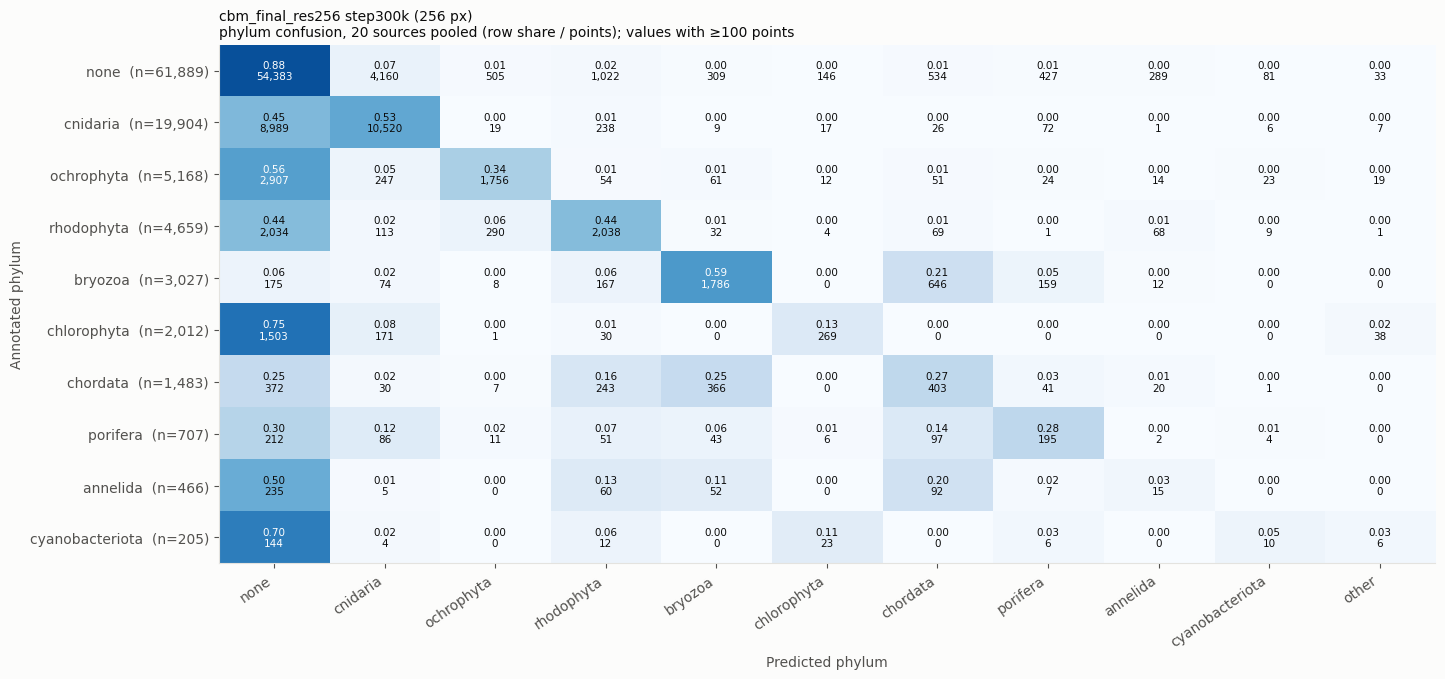

In [12]:
plot_confusion(name0, rank_frame(d0, RANK_P), rank=RANK_P, min_n=100); plt.show()

### Each phylum across sources
Blue / orange: recall / precision of the phylum in each source. Green diamonds: recall only on points whose kingdom is
predicted correctly, i.e. the phylum head's own error. Phyla with ≥ `MIN_GT` points in at least one source.

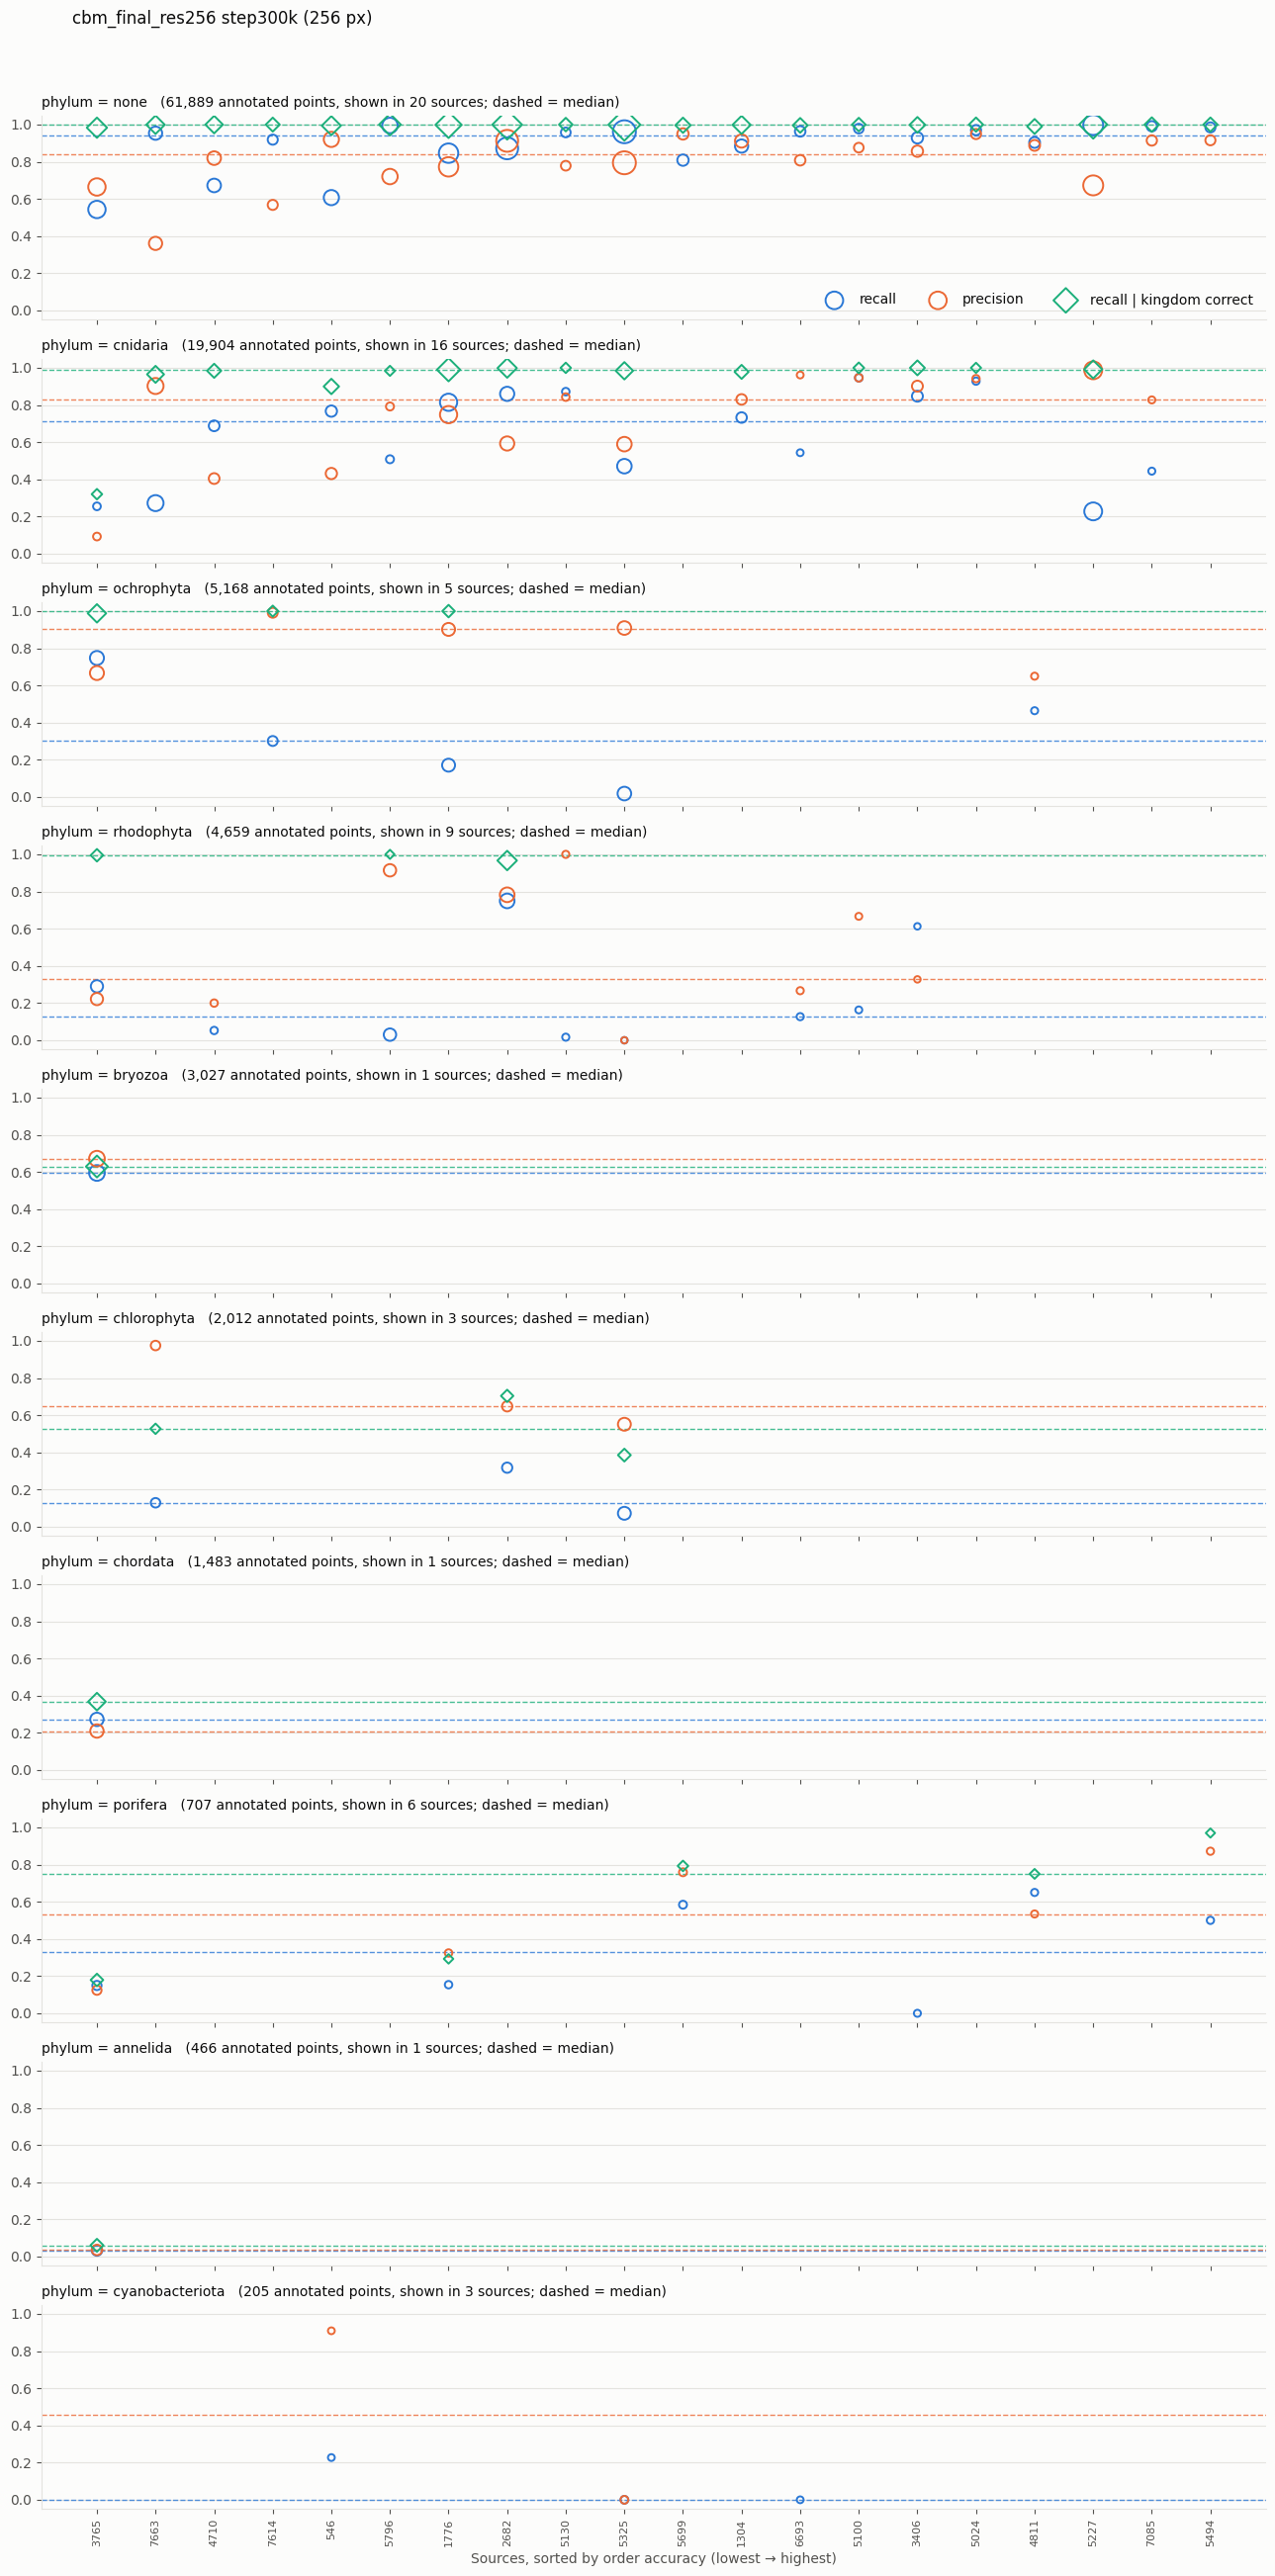

In [13]:
plot_values_across_sources(name0, d0, rank=RANK_P, parent=PARENT_P); plt.show()

### Errors that are not inherited from kingdom
Phylum errors on points whose kingdom is right: which phylum pairs are confused, and the labels behind them.

In [14]:
r = kp[kp.parent_ok & kp.err]
print(f"{len(r):,} of {int(kp.err.sum()):,} phylum errors have the right kingdom; by annotated kingdom:",
      r[f"gt_{PARENT_P}"].astype(str).value_counts().to_dict())
acc_cond = kp[kp.parent_ok].groupby("y_true").agg(points=("err", "size"), accuracy=("err", lambda e: 1 - e.mean()))
display(acc_cond[acc_cond.points >= 50].sort_values("points", ascending=False).round(3)
        .rename_axis(f"annotated phylum (kingdom correct)"))
display(r.groupby(["y_true", "y_pred"]).size().rename("errors").sort_values(ascending=False).head(12).to_frame())

2,886 of 28,209 phylum errors have the right kingdom; by annotated kingdom: {'animalia': 2488, 'plantae': 299, 'none': 80, 'chromista': 19}


,points,accuracy
annotated phylum (kingdom correct),,
none,53583,0.999
cnidaria,10720,0.979
bryozoa,2846,0.628
rhodophyta,2018,0.970
ochrophyta,1690,0.989
chordata,1095,0.367
chlorophyta,507,0.531
porifera,459,0.418
annelida,248,0.060


,,errors
y_true,y_pred,
bryozoa,chordata,646
chordata,bryozoa,366
chlorophyta,none,159
bryozoa,porifera,159
chordata,none,130
cnidaria,none,112
chordata,rhodophyta,102
porifera,chordata,97
annelida,chordata,90


In [15]:
g = r.groupby("source_label_name", observed=True)
lab = pd.DataFrame({"errors": g.size(), "annotated": g.y_true.first(), "top_pred": g.y_pred.agg(lambda s: s.mode().iloc[0]),
                    "sources": g.source_id.agg(lambda s: sorted(s.unique().tolist()))})
lab["label_points"] = kp.groupby("source_label_name", observed=True).size().reindex(lab.index)
lab["error_rate"] = lab.errors / lab.label_points
lab.sort_values("errors", ascending=False).head(15).round(2)

,errors,annotated,top_pred,sources,label_points,error_rate
source_label_name,,,,,,
bryozoan,1060,bryozoa,chordata,"[3765, 4811]",3027,0.35
ascidian (colonial),665,chordata,bryozoa,[3765],1405,0.47
sponge,235,porifera,chordata,"[1304, 1776, 3765, 4710, 5699]",483,0.49
worms: polychaetes,233,annelida,chordata,[3765],465,0.50
halimeda discoidea,143,chlorophyta,none,[5325],1178,0.12
dictyosphaeria,58,chlorophyta,none,[2682],434,0.13
hard coral,36,cnidaria,chordata,[3765],84,0.43
halimeda,35,chlorophyta,rhodophyta,[7663],322,0.11
long sediment-laden algal turf,31,none,chordata,[3765],4253,0.01


In [16]:
# Animal phyla per source, kingdom correct: where the non-coral invertebrates are
a = kp[kp.parent_ok & (kp[f"gt_{PARENT_P}"].astype(str) == "animalia")]
ps = a.groupby("source_id").agg(points=("err", "size"), accuracy=("err", lambda e: 1 - e.mean()),
                                n_phyla=("y_true", "nunique"),
                                non_cnidarian_share=("y_true", lambda s: (s != "cnidaria").mean()))
ps[ps.points >= 30].sort_values("accuracy").round(3)

,points,accuracy,n_phyla,non_cnidarian_share
source_id,,,,
3765,4476,0.506,6,0.983
4811,68,0.647,4,0.941
5699,103,0.835,2,0.796
546,579,0.900,1,0.000
4710,397,0.942,3,0.045
1304,378,0.963,2,0.024
7663,917,0.964,2,0.001
5494,45,0.978,2,0.733
1776,3706,0.982,2,0.011


### Interpretation (cbm_final_res256, 20 sources, seed 0)

Phylum accuracy is 0.72, but **90% of phylum errors are on points whose kingdom is already wrong**: given a correct
kingdom, phylum is right 96% of the time; given a wrong kingdom, 4%. So at phylum the picture is mostly the kingdom one,
one level down:
- `cnidaria` → `none` (45% of cnidarian points, ~9k): two thirds are dead coral (annotated cnidaria, looks like and is
  classed as bare substrate), another 11% octocorals (`cred-octocoral`, source 5325), the rest live corals and soft
  coral missed as background.
- `ochrophyta` / `rhodophyta` / `chlorophyta` → `none` (56% / 44% / 75%) is the algae-vs-turf convention: turf is
  `none` at every rank, other algae are not.

The phylum head's **own** errors (10%, ~2.9k points) are almost all among animals (86%) and almost all in **non-coral
sessile invertebrates**. Given a correct kingdom, cnidaria is 0.98 accurate, but bryozoa 0.63, chordata (ascidians) 0.37,
porifera 0.42 and annelida 0.06. The confusions are between each other: bryozoan ↔ colonial ascidian (≈1,000 points
both ways), sponges and polychaete worms → chordata / bryozoa. These are encrusting, visually similar organisms, and
they come almost entirely from **source 3765** (6 animal phyla, ~4.5k animal points, phylum accuracy 0.51 given
kingdom correct; every other source with enough animals is ≥ 0.83, most ≥ 0.95). The algae phyla add a few hundred more
(*Halimeda*, *Dictyosphaeria* → `none`).

So for typical reef sources phylum adds almost no error of its own beyond kingdom. The two things to look at: the
kingdom encoding issues (fixing them fixes most of phylum), and whether the training data has enough bryozoans,
ascidians, sponges and worms, or whether source 3765 is simply an unusual (fouling-community-like) source.

# Class, order, family and genus

The same analysis for the remaining ranks, through one function. For each rank:
1. **Where its errors are first made.** For every point labelled at this rank, the first rank (from kingdom down)
   whose prediction is wrong. An error "made at this rank" means every rank above was right.
2. Confusion of the most frequent values (rows: top `TOP_VALUES`; columns: the same values, then "other").
3. Each value across sources (top `MAX_PANELS` values), with recall given the parent rank correct (green).
4. The errors made at this rank: confused pairs, the labels behind them, and per-source accuracy on non-`none` points
   when every rank above is right.

In [17]:
TOP_VALUES, MAX_PANELS = 14, 8

def first_wrong_rank(d: PointDump, k: pd.DataFrame, rank: str) -> pd.Series:
    """For each row of k: the first rank from kingdom down to `rank` whose prediction is wrong ("correct" if none).
    Ranks without a label on the point are skipped."""
    out = pd.Series("correct", index=k.index, dtype=object)
    for a in reversed(d.ranks[: d.ranks.index(rank) + 1]):
        g = k[f"gt_{a}"]
        wrong = g.notna() & (g.astype(str) != k[f"pred_{a}"].astype(str))
        out[wrong.to_numpy()] = a
    return out

def analyze_rank(rank: str, name: str = None, d: PointDump = None):
    name, d = (name, d) if d is not None else next(iter(dumps.items()))
    parent = d.ranks[d.ranks.index(rank) - 1]
    k = rank_frame(d, rank)
    k["first_wrong"] = first_wrong_rank(d, k, rank)
    k["err"] = k.y_true != k.y_pred
    origin = k.first_wrong[k.err].value_counts().reindex(d.ranks[: d.ranks.index(rank) + 1]).fillna(0).astype(int)
    errs = int(k.err.sum())
    above_ok = k.first_wrong.isin(["correct", rank])
    print(f"{name} — {rank}: accuracy {1 - k.err.mean():.3f} over {len(k):,} points; "
          f"{errs:,} errors, {int((k.first_wrong == rank).sum()):,} ({(k.first_wrong == rank).sum() / max(errs, 1):.1%}) first made at {rank}.")
    print(f"accuracy when every rank above is right: {1 - k[above_ok].err.mean():.3f} (n={above_ok.sum():,}); "
          f"on non-none points: {1 - k[above_ok & (k.y_true != 'none')].err.mean():.3f}")
    display(pd.DataFrame({"errors": origin.map("{:,}".format), "share_of_errors": (origin / max(errs, 1)).map("{:.1%}".format)})
            .rename_axis(f"{rank} errors by first wrong rank"))
    plot_confusion(name, k, rank=rank, min_n=50, top=TOP_VALUES); plt.show()
    plot_values_across_sources(name, d, rank=rank, parent=parent, max_values=MAX_PANELS); plt.show()

    r = k[k.first_wrong == rank]
    display(r.groupby(["y_true", "y_pred"]).size().rename("errors made at this rank")
            .sort_values(ascending=False).head(10).to_frame())
    g = r.groupby("source_label_name", observed=True)
    lab = pd.DataFrame({"errors": g.size(), "annotated": g.y_true.first(),
                        "top_pred": g.y_pred.agg(lambda s: s.mode().iloc[0]),
                        "sources": g.source_id.agg(lambda s: sorted(s.unique().tolist()))})
    lab["label_points"] = k.groupby("source_label_name", observed=True).size().reindex(lab.index)
    lab["error_rate"] = lab.errors / lab.label_points
    display(lab.sort_values("errors", ascending=False).head(10).round(2))
    nn = k[above_ok & (k.y_true != "none")]
    ps = nn.groupby("source_id").agg(points=("err", "size"), accuracy=("err", lambda e: 1 - e.mean()),
                                     n_values=("y_true", "nunique"))
    display(ps[ps.points >= MIN_GT].sort_values("accuracy").round(3)
            .rename_axis(f"source (non-none, ranks above right)").head(10))

## Class

cbm_final_res256 step300k (256 px) — class: accuracy 0.718 over 95,630 points; 26,923 errors, 1,173 (4.4%) first made at class.
accuracy when every rank above is right: 0.983 (n=68,313); on non-none points: 0.922


,errors,share_of_errors
class errors by first wrong rank,,
kingdom,"24,338",90.4%
phylum,"1,412",5.2%
class,"1,173",4.4%


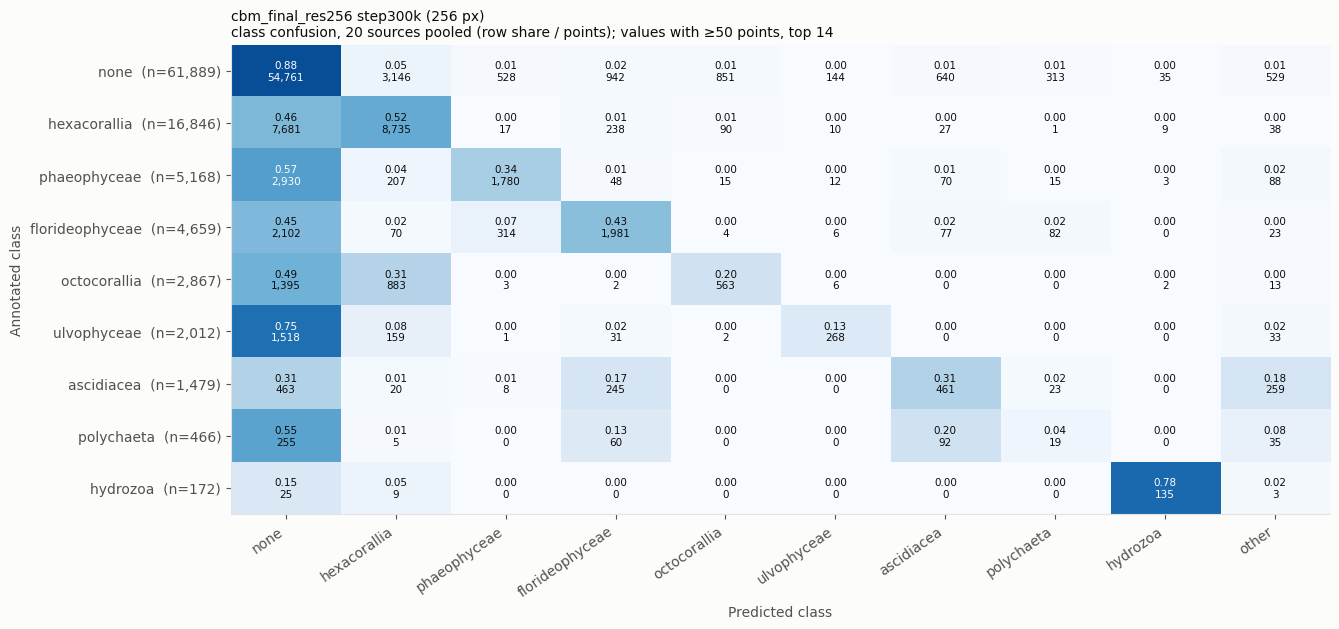

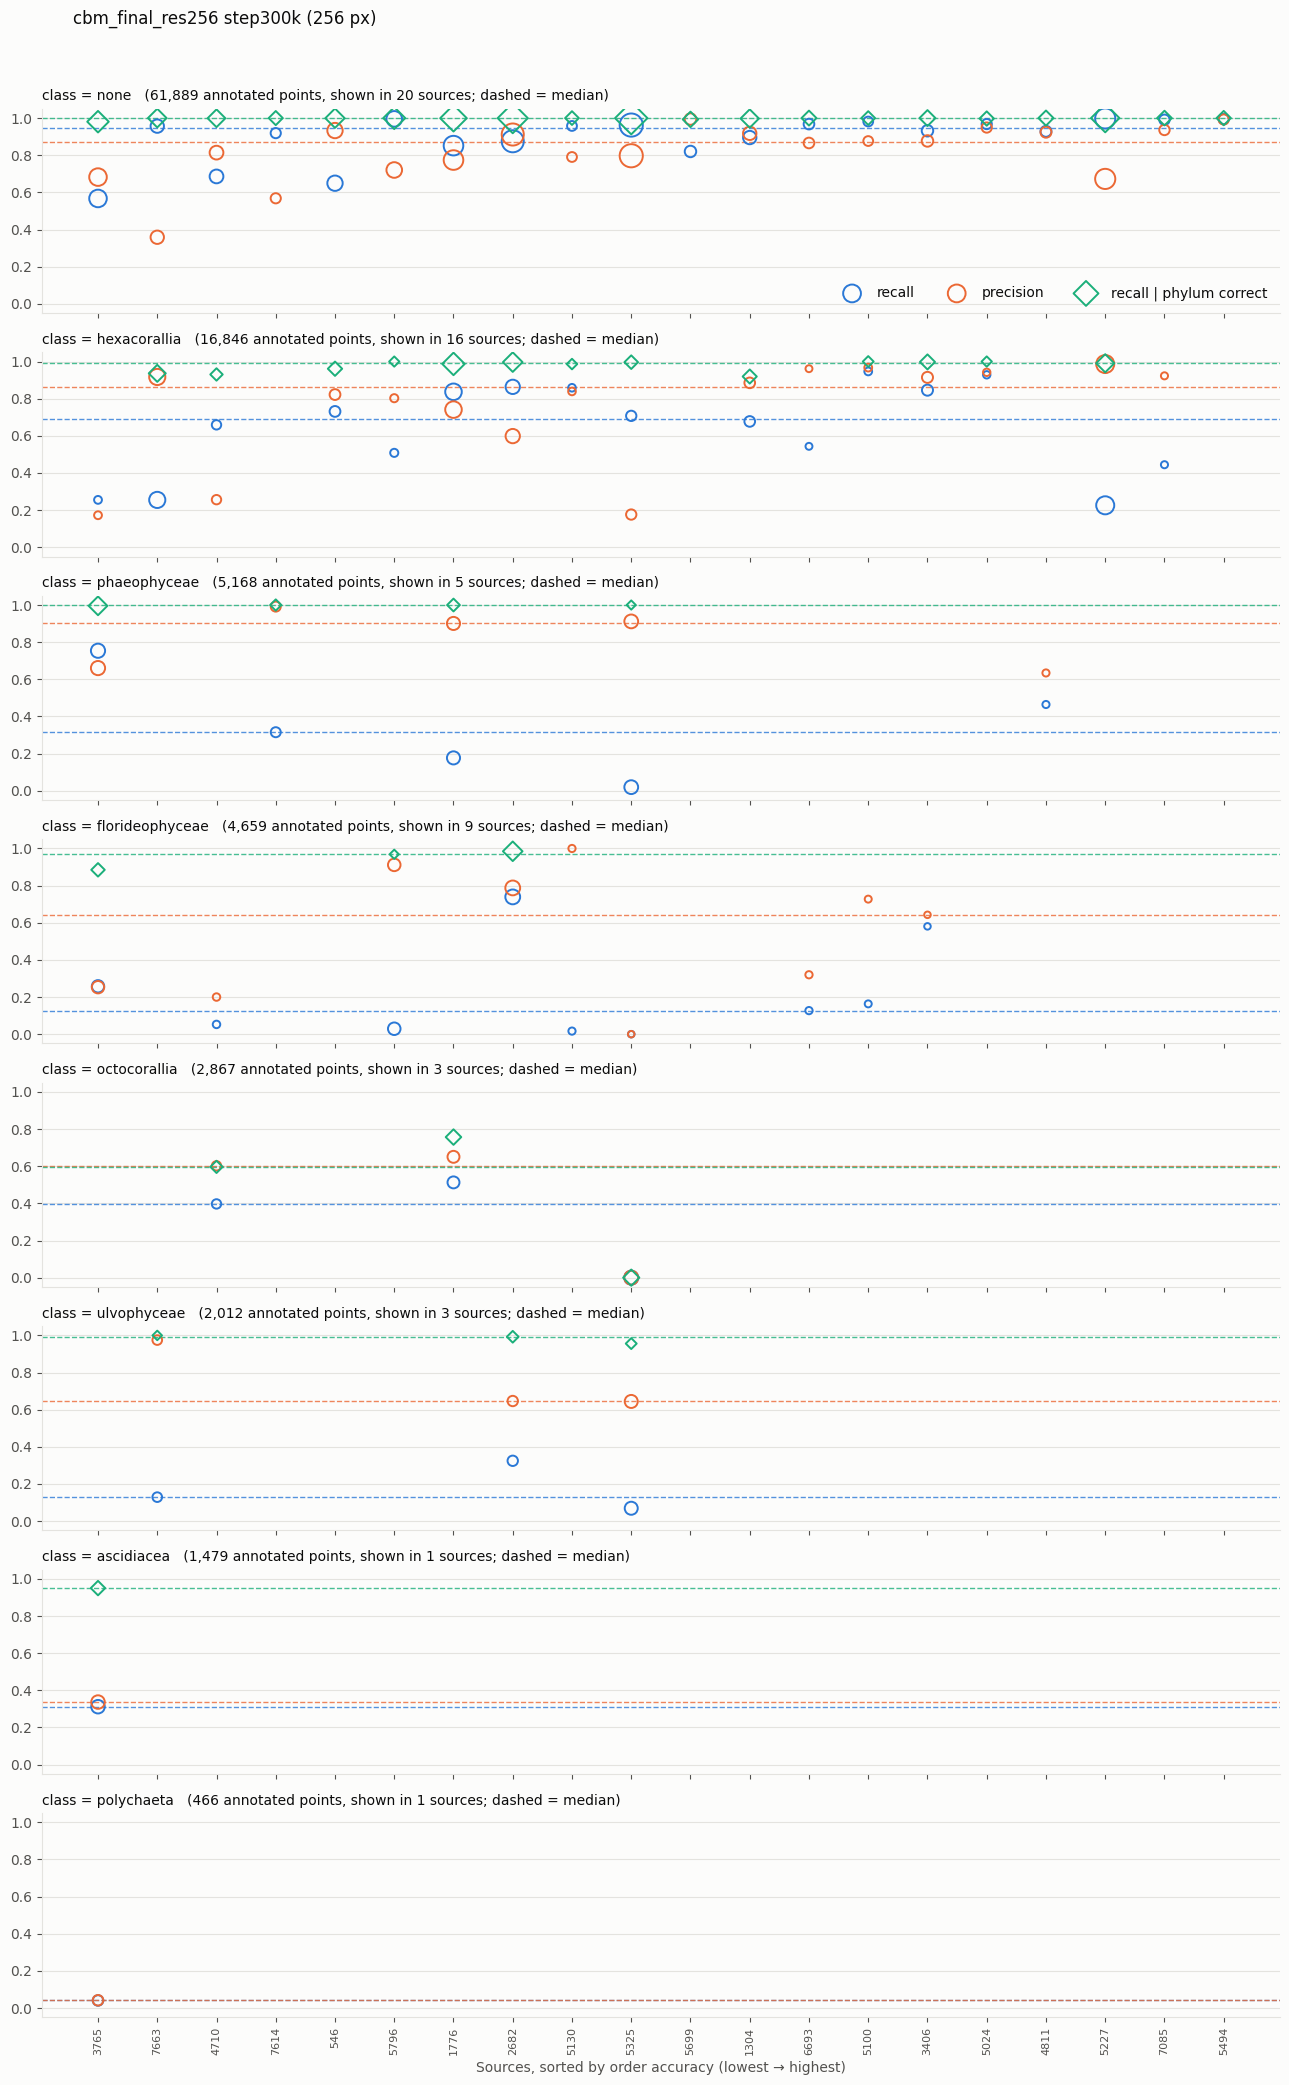

errors made at this rank
y_true          y_pred                                
octocorallia    hexacorallia                       864
hexacorallia    octocorallia                        89
                none                                65
octocorallia    none                                43
florideophyceae none                                31
ascidiacea      none                                12
hexacorallia    hydrozoa                             9
hydrozoa        hexacorallia                         9
none            phaeophyceae                         7
florideophyceae phaeophyceae                         7

,errors,annotated,top_pred,sources,label_points,error_rate
source_label_name,,,,,,
cred-octocoral,696,octocorallia,hexacorallia,[5325],1720,0.40
soft coral,141,octocorallia,hexacorallia,"[1776, 4710]",849,0.17
xeniidae,40,octocorallia,hexacorallia,[4710],185,0.22
dead coral,25,hexacorallia,none,"[5227, 7663]",5692,0.00
sinularia,19,octocorallia,hexacorallia,"[4710, 7663]",41,0.46
ascidian (colonial),18,ascidiacea,none,[3765],1405,0.01
other hard coral,17,hexacorallia,octocorallia,"[1304, 1776]",450,0.04
acropora cervicornis,16,hexacorallia,hydrozoa,[1304],83,0.19
gracilaria salicornia,14,florideophyceae,none,[2682],1239,0.01


,points,accuracy,n_values
"source (non-none, ranks above right)",,,
5325,1114,0.371,4
4710,375,0.752,4
1304,360,0.922,2
7663,923,0.939,3
4811,37,0.946,4
1776,3837,0.954,4
546,521,0.967,2
5130,75,0.973,3
3765,1958,0.983,6


In [18]:
analyze_rank("class")

**Class.** 96% of class errors are inherited (90% from kingdom, 5% from phylum). Given everything above is right, class is 0.98
accurate (0.92 on non-`none` points). The errors class adds (~1.2k) are almost all **octocorals predicted as
hexacorals**: `cred-octocoral` in source 5325 (≈700) plus soft coral / *Xenia* / *Sinularia* in 1776, 4710, 7663.
Octocorallia is 0.38 accurate given the phylum is right; hexacorallia 0.98. Source 5325 is the outlier (0.37 on
non-`none` points; every other source ≥ 0.75).

## Order

cbm_final_res256 step300k (256 px) — order: accuracy 0.777 over 86,053 points; 19,224 errors, 1,752 (9.1%) first made at order.
accuracy when every rank above is right: 0.974 (n=66,405); on non-none points: 0.866


,errors,share_of_errors
order errors by first wrong rank,,
kingdom,"16,587",86.3%
phylum,494,2.6%
class,391,2.0%
order,"1,752",9.1%


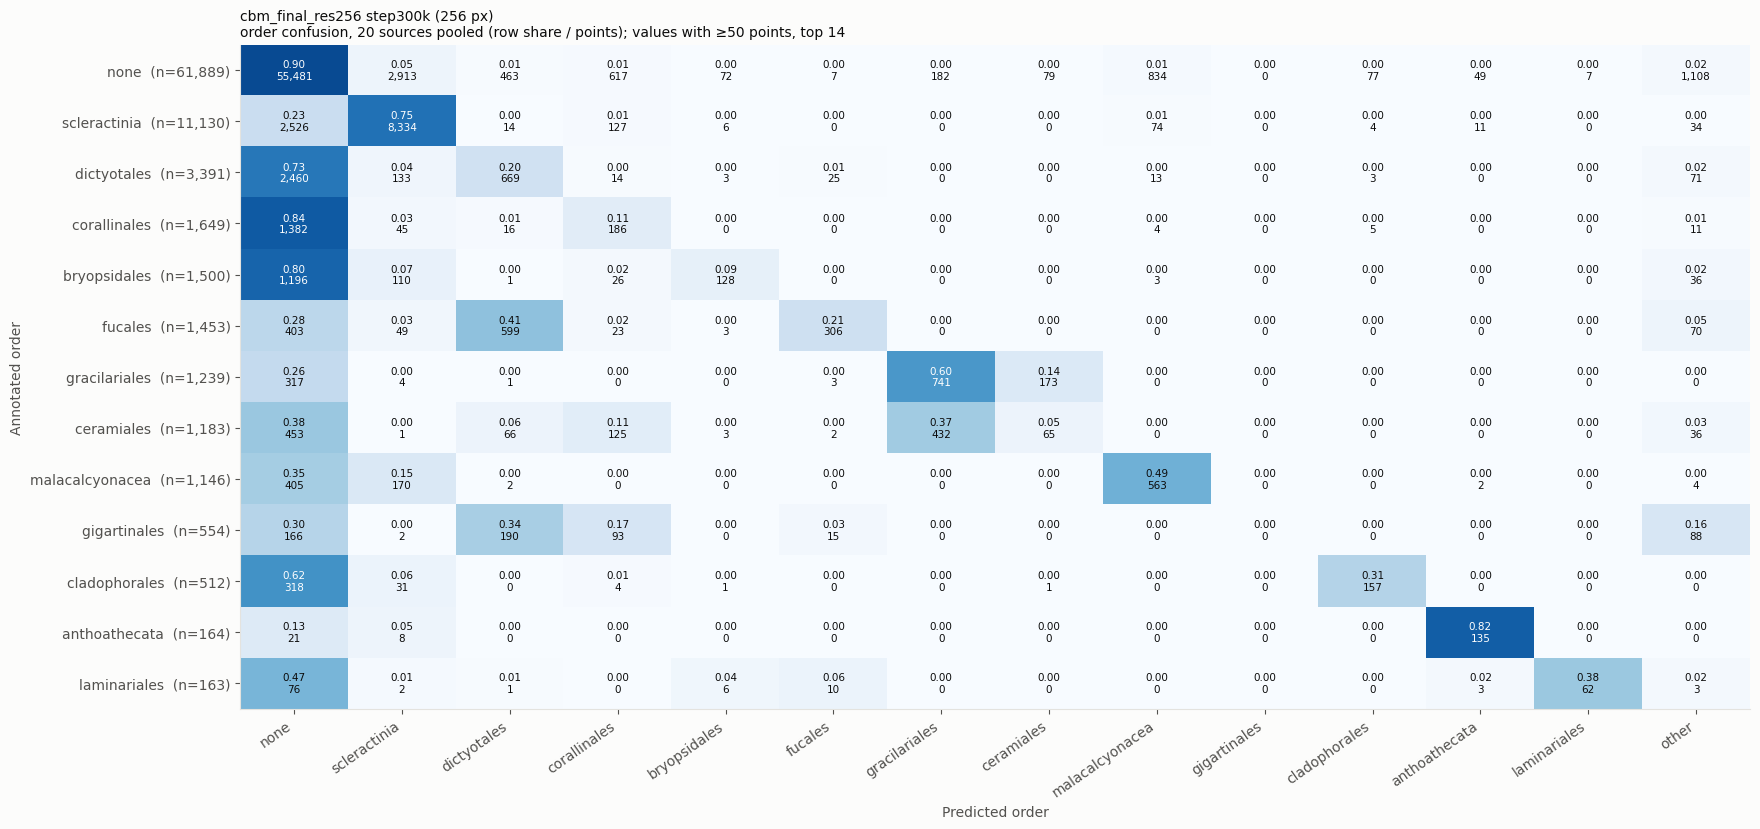

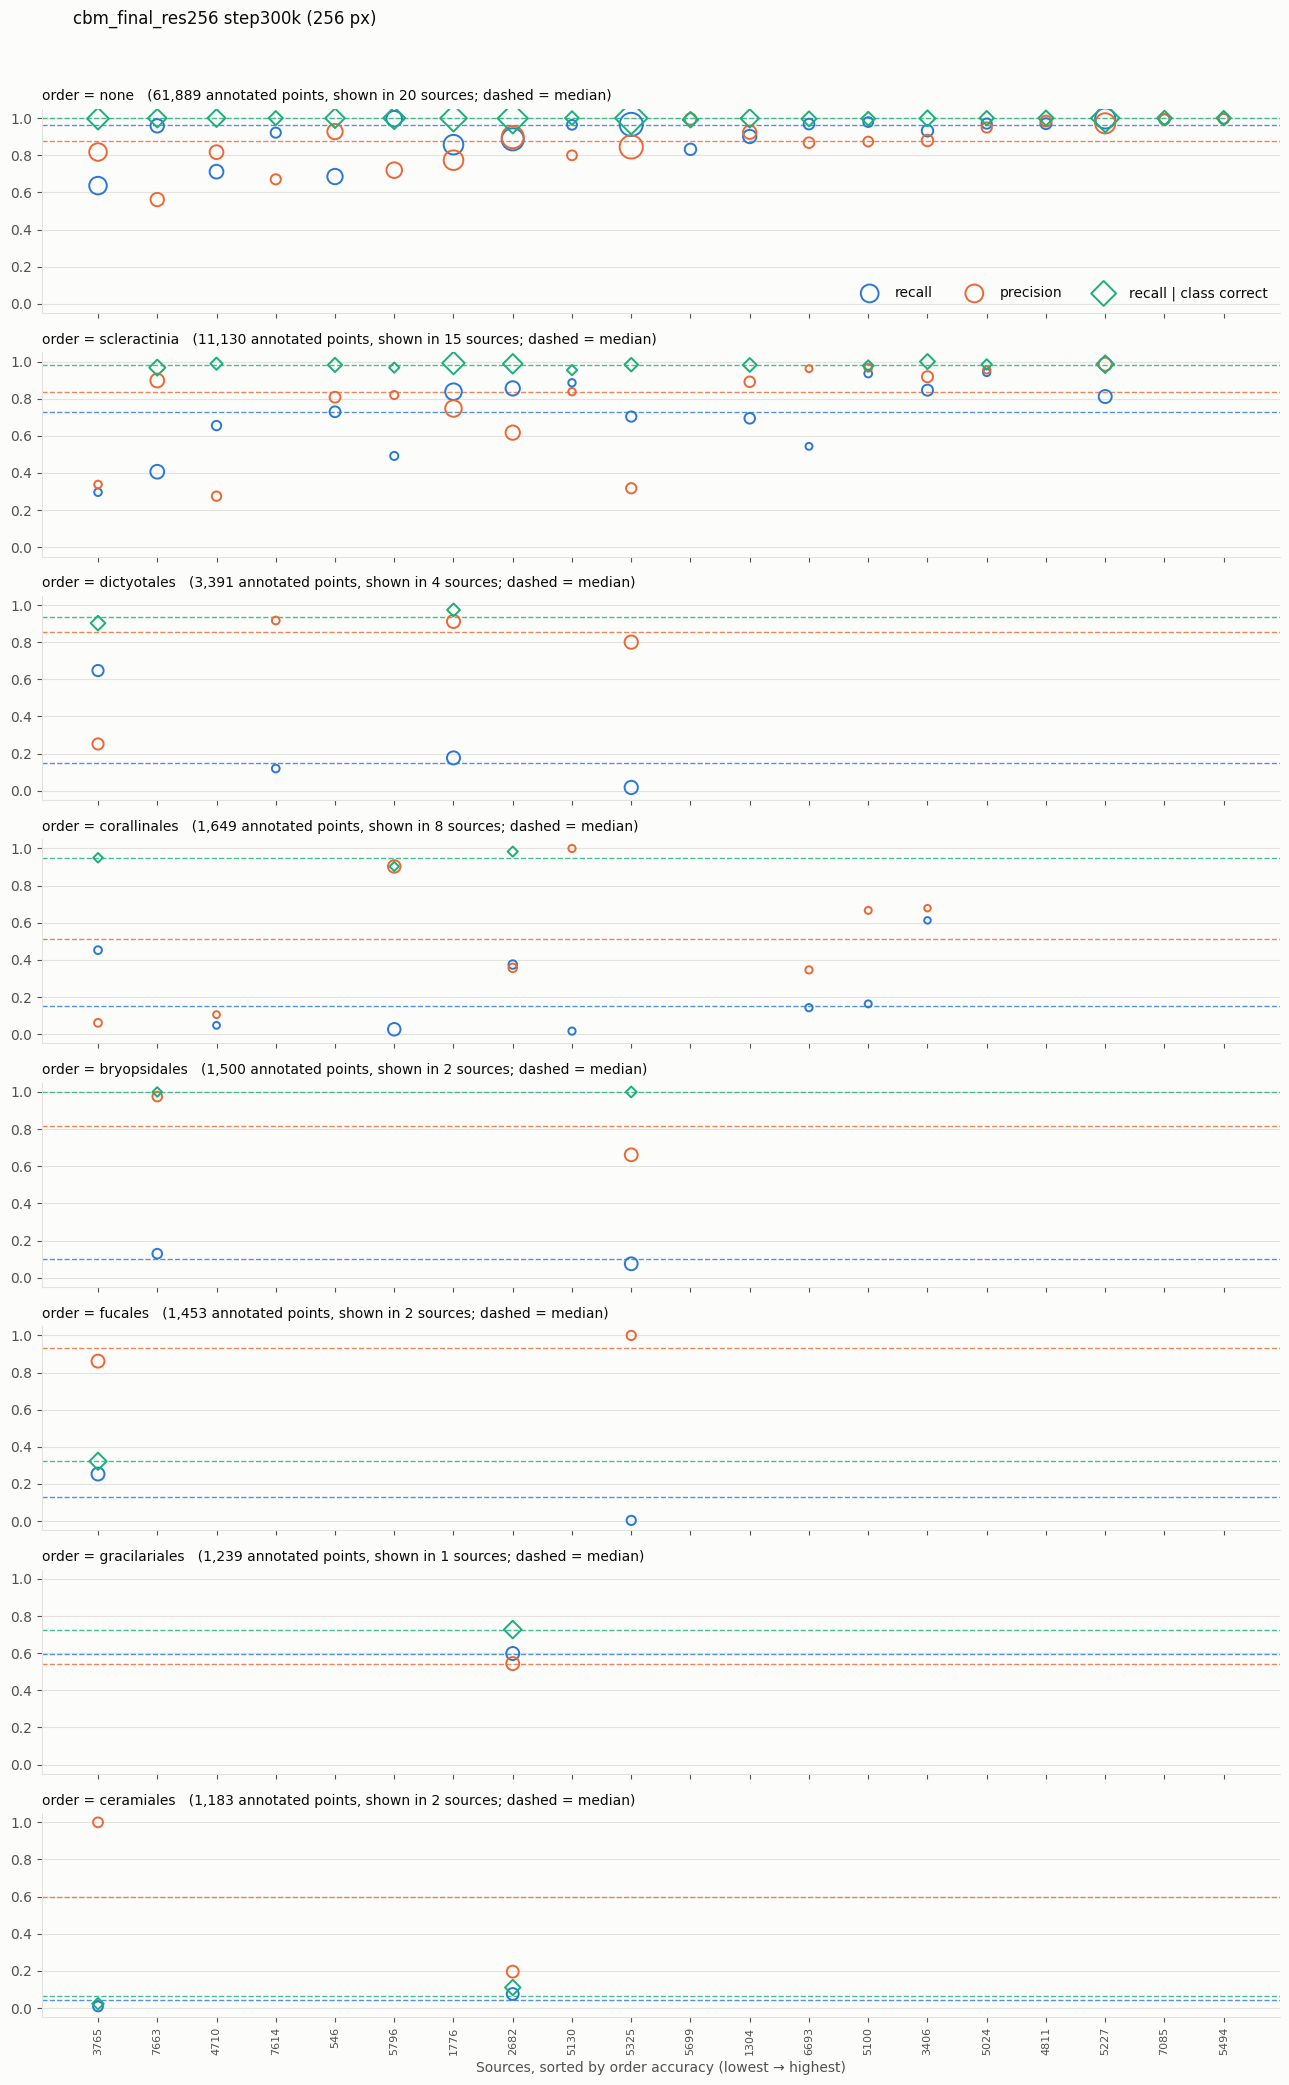

errors made at this rank
y_true        y_pred                                 
fucales       dictyotales                         570
ceramiales    gracilariales                       431
gracilariales ceramiales                          173
              none                                105
scleractinia  none                                100
ceramiales    corallinales                         98
              none                                 71
gigartinales  corallinales                         47
fucales       none                                 30
dictyotales   fucales                              25

,errors,annotated,top_pred,sources,label_points,error_rate
source_label_name,,,,,,
sargassum,601,fucales,dictyotales,"[3765, 4811, 5325]",1435,0.42
spyridia filamentosa,498,ceramiales,gracilariales,[2682],807,0.62
gracilaria salicornia,278,gracilariales,ceramiales,[2682],1239,0.22
chondria species,106,ceramiales,corallinales,[3765],340,0.31
hypnea,54,gigartinales,corallinales,[3765],554,0.10
ecklonia radiata,28,laminariales,none,[7614],163,0.17
dictyota,22,dictyotales,fucales,[3765],391,0.06
padina,14,dictyotales,fucales,"[1776, 3765, 7614]",2689,0.01
porites compressa,12,scleractinia,none,"[2682, 5325]",1290,0.01


,points,accuracy,n_values
"source (non-none, ranks above right)",,,
3765,1528,0.480,6
7614,102,0.706,2
2682,3422,0.766,6
5796,91,0.945,2
7663,714,0.969,3
5130,65,0.969,2
5024,74,0.973,2
5325,413,0.978,5
4710,282,0.979,4


In [19]:
analyze_rank("order")

**Order.** 91% inherited (86% from kingdom); 0.97 given everything above right (0.87 on non-`none`). Scleractinia is 0.99. The errors
order adds (~1.8k) are **between algal orders**: *Sargassum* (Fucales) → Dictyotales (≈600, sources 3765 / 4811 /
5325), *Spyridia* (Ceramiales) ↔ *Gracilaria* (Gracilariales) in source 2682 (≈700 both ways), and *Chondria* /
*Hypnea* → Corallinales in 3765. Ceramiales is 0.10 accurate, Fucales 0.33, Gracilariales 0.73. The sources are
3765 (0.48) and 2682 (0.77) — the two with many algae orders.

## Family

cbm_final_res256 step300k (256 px) — family: accuracy 0.802 over 82,123 points; 16,244 errors, 1,208 (7.4%) first made at family.
accuracy when every rank above is right: 0.981 (n=63,575); on non-none points: 0.881


,errors,share_of_errors
family errors by first wrong rank,,
kingdom,"12,759",78.5%
phylum,383,2.4%
class,212,1.3%
order,"1,682",10.4%
family,"1,208",7.4%


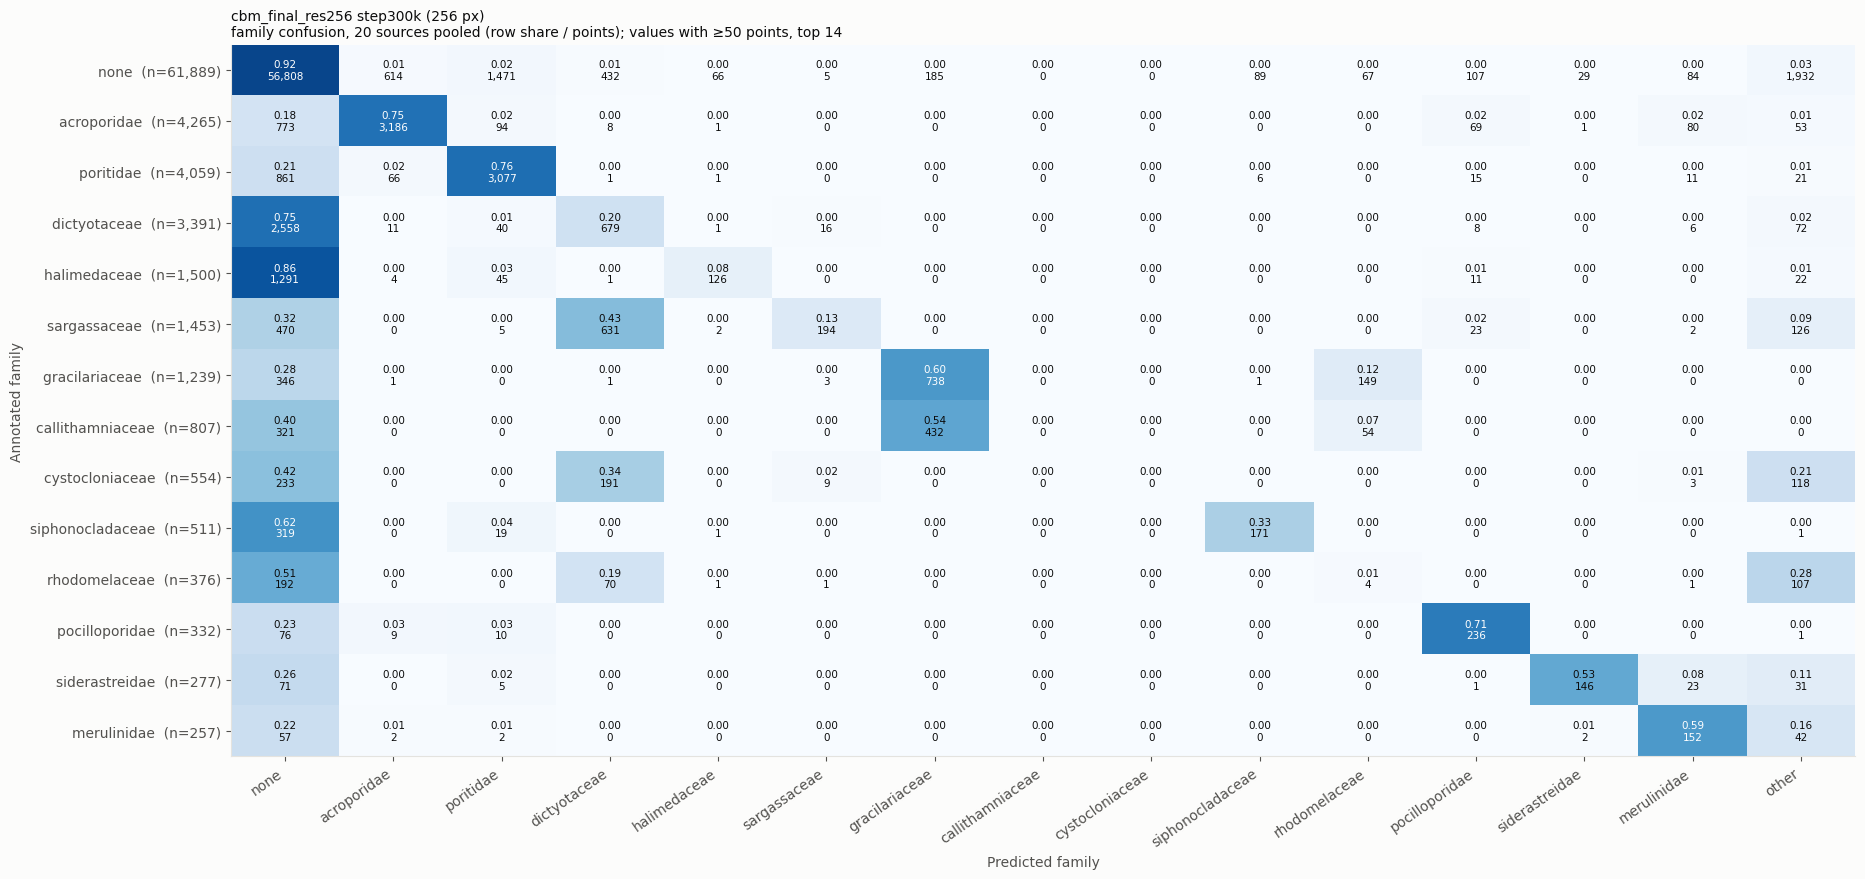

/tmp/ipykernel_1225449/3202505996.py:24: RuntimeWarning: All-NaN slice encountered
  ax.axhline(np.nanmedian(y), color=c, lw=1, ls="--", alpha=0.8)


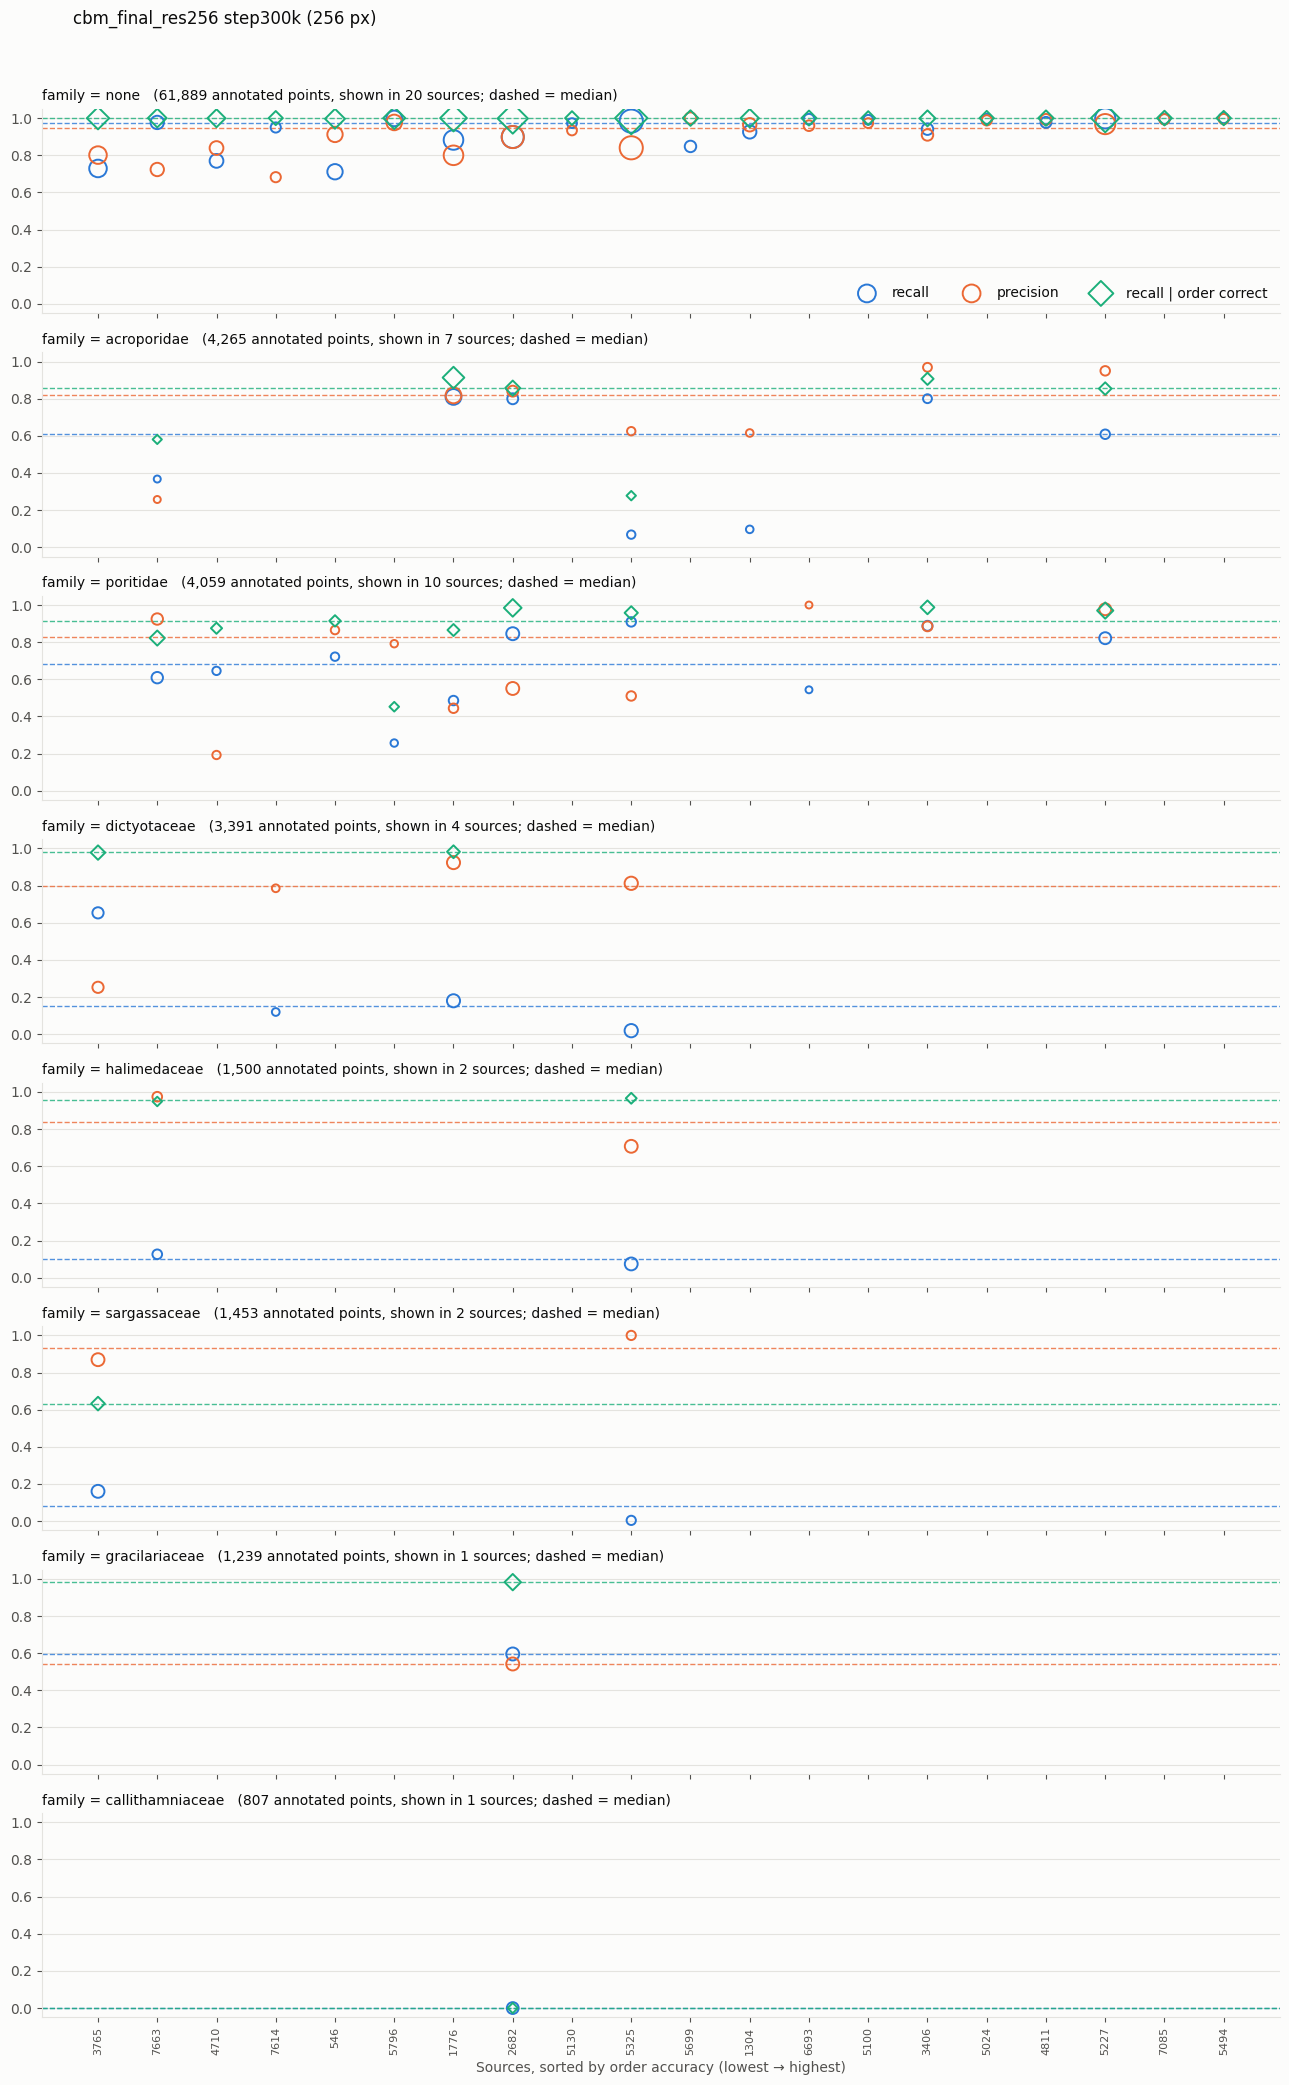

errors made at this rank
y_true           y_pred                                  
acroporidae      none                                 136
poritidae        none                                 109
acroporidae      poritidae                             93
                 merulinidae                           80
                 pocilloporidae                        67
poritidae        acroporidae                           66
callithamniaceae rhodomelaceae                         54
sargassaceae     fucaceae                              42
                 dictyotaceae                          41
mussidae         merulinidae                           36

,errors,annotated,top_pred,sources,label_points,error_rate
source_label_name,,,,,,
acroporidae (plate/encrusting),167,acroporidae,merulinidae,[1776],982,0.17
montipora capitata,115,acroporidae,pocilloporidae,"[2682, 3406, 5325]",896,0.13
sargassum,105,sargassaceae,fucaceae,[3765],1435,0.07
favidae-mussidae massive/meandroid,69,mussidae,merulinidae,[1776],116,0.59
spyridia filamentosa,62,callithamniaceae,rhodomelaceae,[2682],807,0.08
leptastrea purpurea,35,leptastreidae,none,[2682],108,0.32
porites lutea,32,poritidae,none,[7663],424,0.08
xeniidae,31,xeniidae,none,[4710],185,0.17
porites cylindrica,29,poritidae,acroporidae,[7663],110,0.26


,points,accuracy,n_values
"source (non-none, ranks above right)",,,
5796,59,0.542,4
5130,62,0.613,4
7614,72,0.639,2
4710,221,0.652,12
7663,625,0.781,8
546,498,0.801,8
3765,709,0.821,4
5024,64,0.859,4
1776,3157,0.893,6


In [20]:
analyze_rank("family")

**Family.** 93% inherited (79% from kingdom, 10% from order); 0.98 given everything above right (0.88 on non-`none`). This is the first rank where
**coral** errors appear on their own (~1.2k): Acroporidae ↔ Poritidae / Merulinidae / Pocilloporidae, *Montipora
capitata* → Pocilloporidae (2682, 3406, 5325), `acroporidae (plate/encrusting)` → Merulinidae and `favidae-mussidae
massive/meandroid` → Merulinidae (1776), plus Acroporidae / Poritidae → `none`. Mussidae (0.46), Siderastreidae (0.69)
and Merulinidae (0.71) are the weakest; Acroporidae 0.89, Poritidae 0.94. Some of this is label granularity:
`favidae-mussidae` is a two-family label and `acroporidae (plate/encrusting)` a growth-form label mapped to one family.
Per source the weakest are small (5796, 5130, 7614 < 75 points) or diverse (4710, 12 families, 0.65).

## Genus

cbm_final_res256 step300k (256 px) — genus: accuracy 0.804 over 78,801 points; 15,449 errors, 430 (2.8%) first made at genus.
accuracy when every rank above is right: 0.993 (n=59,906); on non-none points: 0.935


,errors,share_of_errors
genus errors by first wrong rank,,
kingdom,"12,033",77.9%
phylum,360,2.3%
class,150,1.0%
order,"1,642",10.6%
family,834,5.4%
genus,430,2.8%


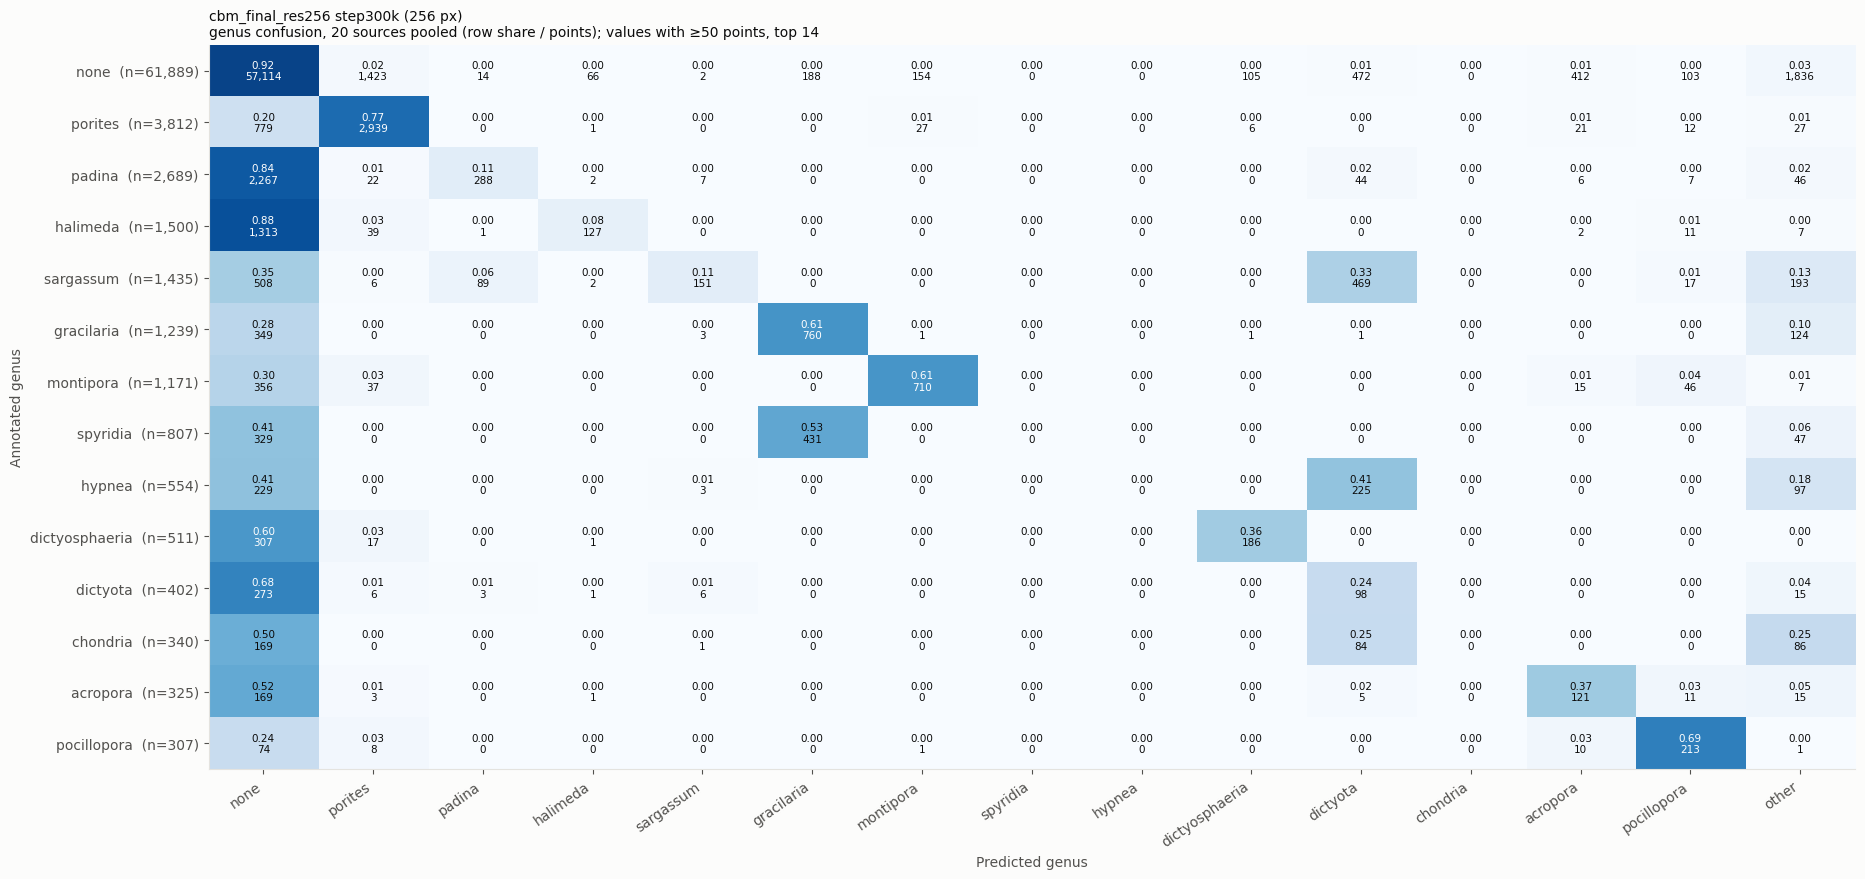

/tmp/ipykernel_1225449/3202505996.py:24: RuntimeWarning: All-NaN slice encountered
  ax.axhline(np.nanmedian(y), color=c, lw=1, ls="--", alpha=0.8)


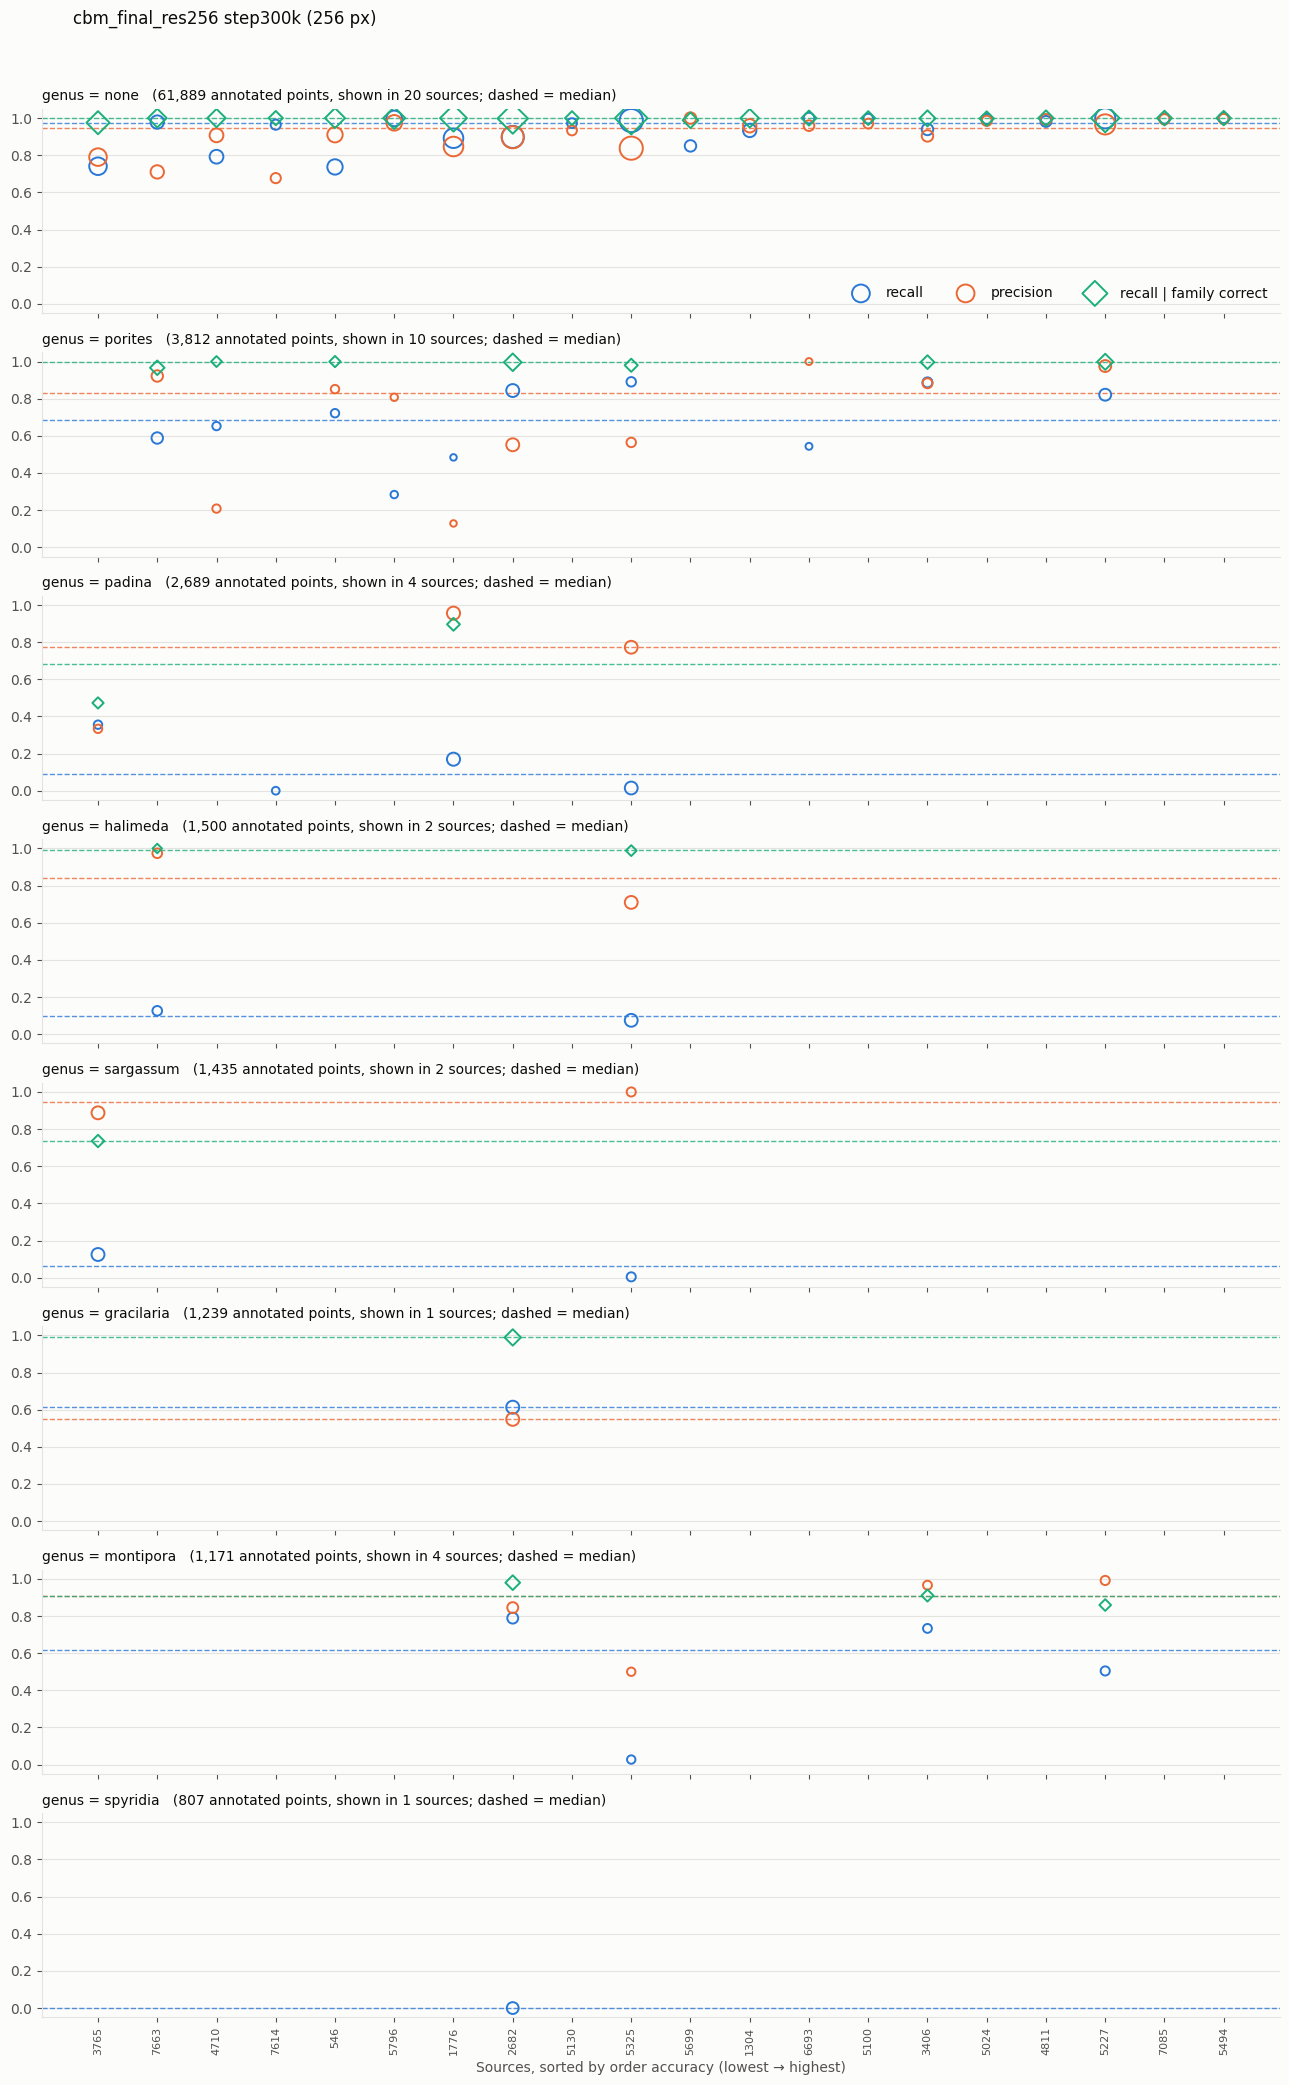

,,errors made at this rank
y_true,y_pred,
lobophora,dictyota,111
padina,dictyota,43
montipora,none,29
padina,lobophora,22
sargassum,fucus,22
porites,none,20
sargassum,none,18
padina,none,17
montipora,acropora,15


,errors,annotated,top_pred,sources,label_points,error_rate
source_label_name,,,,,,
lobophora,139,lobophora,dictyota,[3765],300,0.46
padina,82,padina,dictyota,"[1776, 3765, 5325, 7614]",2689,0.03
sargassum,50,sargassum,fucus,[3765],1435,0.03
montipora capitata,29,montipora,none,"[2682, 3406, 5325]",896,0.03
montipora,19,montipora,none,[5227],232,0.08
stylophora,14,stylophora,pocillopora,[1776],19,0.74
amphiroa sp.,11,amphiroa,dictyota,[3765],98,0.11
porites lutea,10,porites,none,[7663],424,0.02
long sediment-laden algal turf,7,none,dictyota,[3765],4253,0.00


,points,accuracy,n_values
"source (non-none, ranks above right)",,,
3765,582,0.555,6
7614,46,0.674,2
5796,32,0.906,3
1776,398,0.940,7
5325,367,0.946,6
7663,488,0.957,5
546,399,0.970,6
3406,472,0.970,2
4710,105,0.971,6


In [21]:
analyze_rank("genus", )

**Genus.** 97% inherited (78% from kingdom, 11% from order, 5% from family); 0.99 given everything above right (0.94 on non-`none`). Genus adds only ~430 errors, mostly
**brown algae in source 3765** (*Lobophora* / *Padina* → *Dictyota*, *Sargassum* → *Fucus*) and a few *Montipora* /
*Porites* → `none`. Given the family is right, the coral genera are 0.93–0.99 (*Porites* 0.99, *Montipora* 0.93,
*Pocillopora* 0.97, *Acropora* 0.96).

## Across ranks: where the errors are made
For each rank, its error rate split by the rank at which the error is first made (stacked, sums to the rank's error
rate); each segment shows its share of the rank's points and the number of points. The table below gives the same
as counts: per rank, the errors made at that rank itself and those inherited, and the origin of every error as
"count (% of that rank's errors)". Points without a label at a rank above are not counted as wrong there. `right here, wrong above`: points predicted
correctly at the rank although a rank above is wrong (each rank has its own head, so they can disagree); they are not
errors and are not in the bars.

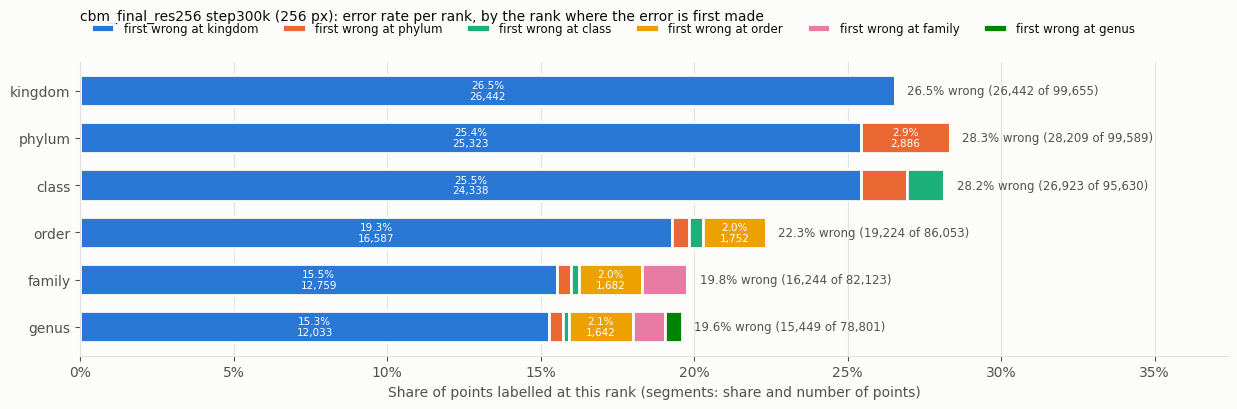

cbm_final_res256 step300k (256 px): errors per rank by where they are first made — count (% of that rank's errors)


,points,errors,error rate,made at this rank,inherited from above,"right here, wrong above",first wrong at kingdom,first wrong at phylum,first wrong at class,first wrong at order,first wrong at family,first wrong at genus
rank,,,,,,,,,,,,
kingdom,"99,655","26,442",26.5%,"26,442 (100.0%)",0 (0.0%),0,"26,442 (100.0%)",,,,,
phylum,"99,589","28,209",28.3%,"2,886 (10.2%)","25,323 (89.8%)","1,075","25,323 (89.8%)","2,886 (10.2%)",,,,
class,"95,630","26,923",28.2%,"1,173 (4.4%)","25,750 (95.6%)","1,567","24,338 (90.4%)","1,412 (5.2%)","1,173 (4.4%)",,,
order,"86,053","19,224",22.3%,"1,752 (9.1%)","17,472 (90.9%)","2,176","16,587 (86.3%)",494 (2.6%),391 (2.0%),"1,752 (9.1%)",,
family,"82,123","16,244",19.8%,"1,208 (7.4%)","15,036 (92.6%)","3,512","12,759 (78.5%)",383 (2.4%),212 (1.3%),"1,682 (10.4%)","1,208 (7.4%)",
genus,"78,801","15,449",19.6%,430 (2.8%),"15,019 (97.2%)","3,876","12,033 (77.9%)",360 (2.3%),150 (1.0%),"1,642 (10.6%)",834 (5.4%),430 (2.8%)


In [22]:
RANK_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # categorical slots 1-6, in rank order

def error_origin_counts(d: PointDump) -> pd.DataFrame:
    """Per rank: points labelled at the rank; for the points wrong at this rank, the first rank (kingdom → this rank)
    whose prediction is wrong; and the points right at this rank although a rank above is wrong."""
    rows = []
    for rank in d.ranks:
        k = rank_frame(d, rank)
        err = k.y_true != k.y_pred
        fw = first_wrong_rank(d, k, rank)
        origin = fw[err].value_counts()
        rows.append({"rank": rank, "points": len(k), **{a: int(origin.get(a, 0)) for a in d.ranks},
                     "right_here_wrong_above": int((~err & (fw != "correct")).sum())})
    return pd.DataFrame(rows).set_index("rank")

def error_origin_table(counts: pd.DataFrame, ranks: list[str]) -> pd.DataFrame:
    """Readable summary: errors, error rate, errors made at the rank itself, and the origin of the rest ("n (% of errors)")."""
    errors = counts[ranks].sum(axis=1)
    own = pd.Series({r: counts.at[r, r] for r in counts.index})
    out = pd.DataFrame({
        "points": counts.points.map("{:,}".format),
        "errors": errors.map("{:,}".format),
        "error rate": (errors / counts.points).map("{:.1%}".format),
        "made at this rank": [f"{o:,} ({o / e:.1%})" if e else "–" for o, e in zip(own, errors)],
        "inherited from above": [f"{e - o:,} ({(e - o) / e:.1%})" if e else "–" for o, e in zip(own, errors)],
        "right here, wrong above": counts.right_here_wrong_above.map("{:,}".format),
    })
    for a in ranks:
        out[f"first wrong at {a}"] = [
            (f"{counts.at[r, a]:,} ({counts.at[r, a] / e:.1%})" if ranks.index(a) <= ranks.index(r) else "")
            for r, e in zip(counts.index, errors)]
    return out

def plot_error_origin(name: str, d: PointDump, counts: pd.DataFrame):
    t = counts[d.ranks].div(counts.points, axis=0)
    fig, ax = plt.subplots(figsize=(13, 4.2))
    y = np.arange(len(t))[::-1]
    left = np.zeros(len(t))
    for a, c in zip(d.ranks, RANK_COLORS):
        w = t[a].to_numpy()
        ax.barh(y, w, left=left, color=c, height=0.66, edgecolor=SURFACE, linewidth=2, label=f"first wrong at {a}")
        for yi, (l, wi, n) in enumerate(zip(left, w, counts[a])):
            if wi >= 0.018:
                ax.text(l + wi / 2, y[yi], f"{wi:.1%}\n{n:,}", ha="center", va="center", fontsize=7.5,
                        color="white", linespacing=1.1)
        left += w
    for yi, (tot, r) in enumerate(zip(left, counts.index)):
        n_err = int(counts.loc[r, d.ranks].sum())
        ax.text(tot + 0.004, y[yi], f"{tot:.1%} wrong ({n_err:,} of {counts.at[r, 'points']:,})",
                va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(y, t.index)
    ax.set_xlim(0, left.max() * 1.32)
    ax.set_xlabel("Share of points labelled at this rank (segments: share and number of points)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=6, loc="upper left", bbox_to_anchor=(0, 1.17), fontsize=8.5)
    ax.set_title(f"{name}: error rate per rank, by the rank where the error is first made", loc="left", fontsize=10, pad=30)
    fig.tight_layout()
    return fig

for name, d in dumps.items():
    counts = error_origin_counts(d)
    plot_error_origin(name, d, counts); plt.show()
    print(f"{name}: errors per rank by where they are first made — count (% of that rank's errors)")
    display(error_origin_table(counts, d.ranks))

### Overall interpretation (cbm_final_res256, 20 sources, seed 0)

**The errors are made at the top of the hierarchy and carried down.** At every rank below kingdom, 90–97% of errors
are first made at a rank above, and kingdom alone is where 78–90% of them start (see the table above), and given that every rank above is right, each rank is 0.97–0.99
accurate (0.87–0.94 on non-`none` points). Kingdom alone accounts for most of the error at every rank; phylum adds
the non-coral invertebrate confusions; class, order, family and genus each add only a few percent.

What each rank adds on its own, in order of size:
- **kingdom** — living things predicted `none`, driven by the concept table: dead coral is `animalia`, turf is
  `none` while other algae are not, catch-all labels are `none` (see the kingdom section).
- **phylum** — encrusting non-coral invertebrates (bryozoans, ascidians, sponges, worms), almost all in source 3765.
- **class** — octocorals predicted as hexacorals (source 5325 `cred-octocoral`, soft corals).
- **order** — algal orders (*Sargassum*, *Spyridia*, *Gracilaria*, *Chondria*) in sources 2682 and 3765.
- **family** — the first real coral confusions (Acroporidae vs Poritidae / Merulinidae / Pocilloporidae,
  *Montipora capitata*), partly from coarse multi-family labels.
- **genus** — brown algae genera in 3765; coral genera are 0.93–0.99 once the family is right.

So the poor genus-level numbers are not a fine-grained taxonomy problem. **Fixing the kingdom-level label encoding
(dead coral, turf vs other algae, catch-all labels) would fix most of the error at every rank.** After that the
remaining issues are concentrated in a few sources with unusual taxa (3765: fouling invertebrates and algae; 5325:
octocorals; 2682: red algae) rather than spread across the test set.

# Live hard coral only

The same per-source view with the ground truth restricted to **live hard coral**: `live` = True and order
Scleractinia. Two views (definitions identical to `Model_Comparison_256_vs_768.ipynb`, which runs them on all 144
sources for both final models):

1. **Per-rank accuracy on live hard coral points** — how much of the annotated live coral gets the right kingdom,
   phylum, …, genus. Recall-type: false alarms on other substrate are invisible here.
2. **Live hard coral detection on all points** — predicted positive if the order head says Scleractinia and
   p(`live`) > 0.5. A point is negative if `live` = False (dead coral included) or an annotated rank rules
   Scleractinia out; points with neither (e.g. `live` not given) are skipped.

Sources in `SOURCE_ORDER` as above; a source is shown at a rank only with ≥ `MIN_LIVE` live hard coral points labelled
there.

In [23]:
MIN_LIVE = 30
LIVE_THR = 0.5
HARD_CORAL_ANCESTORS = {"kingdom": {"animalia"}, "phylum": {"cnidaria"}, "class": {"hexacorallia", "anthozoa"},
                        "order": {"scleractinia"}}

def live_hard_coral(df: pd.DataFrame) -> pd.Series:
    # 1 = live hard coral, 0 = not, NaN = undetermined.
    pos = (df.gt__live == 2) & (df.gt_order.astype(str) == "scleractinia")
    neg = df.gt__live == 1
    for r, ok in HARD_CORAL_ANCESTORS.items():
        neg |= df[f"gt_{r}"].notna() & ~df[f"gt_{r}"].astype(str).isin(ok)
    return pd.Series(np.where(pos, 1.0, np.where(neg, 0.0, np.nan)), index=df.index)

def live_rank_table(d: PointDump) -> pd.DataFrame:
    df = d.df; lhc = live_hard_coral(df) == 1
    rows = []
    for rank in d.ranks:
        x = df[lhc & df[f"gt_{rank}"].notna()]
        ok = x[f"gt_{rank}"].astype(str) == x[f"pred_{rank}"].astype(str)
        g = ok.groupby(x.source_id)
        rows.append(pd.DataFrame({"live_accuracy": g.mean(), "live_n": g.size()}).assign(rank=rank).reset_index())
    return pd.concat(rows, ignore_index=True)

def live_detection_table(d: PointDump) -> pd.DataFrame:
    df = d.df; y = live_hard_coral(df)
    m = y.notna(); y = y[m] == 1
    p = (df.loc[m, "pred_order"].astype(str) == "scleractinia") & (df.loc[m, "p__live"] > LIVE_THR)
    t = pd.DataFrame({"tp": y & p, "fp": ~y & p, "fn": y & ~p, "source_id": df.loc[m, "source_id"]}).groupby("source_id").sum()
    t["precision"] = t.tp / (t.tp + t.fp); t["recall"] = t.tp / (t.tp + t.fn); t["f1"] = 2 * t.tp / (2 * t.tp + t.fp + t.fn)
    t["n_live"] = t.tp + t.fn
    return t

live_tables = {name: live_rank_table(d) for name, d in dumps.items()}
live_det = {name: live_detection_table(d) for name, d in dumps.items()}
for name, d in dumps.items():
    n = int((live_hard_coral(d.df) == 1).sum())
    tot = live_det[name][["tp", "fp", "fn"]].sum()
    print(f"{name}: {n:,} live hard coral points; pooled detection precision {tot.tp / (tot.tp + tot.fp):.3f}, "
          f"recall {tot.tp / (tot.tp + tot.fn):.3f}, F1 {2 * tot.tp / (2 * tot.tp + tot.fp + tot.fn):.3f}")
    lt = live_tables[name]
    print(pd.DataFrame({r: {"pooled": (lt[lt["rank"] == r].live_accuracy * lt[lt["rank"] == r].live_n).sum() / lt[lt["rank"] == r].live_n.sum(),
                            "mean over sources": lt[(lt["rank"] == r) & (lt.live_n >= MIN_LIVE)].live_accuracy.mean(),
                            "median over sources": lt[(lt["rank"] == r) & (lt.live_n >= MIN_LIVE)].live_accuracy.median()}
                        for r in d.ranks}).round(3).to_string())

cbm_final_res256 step300k (256 px): 10,312 live hard coral points; pooled detection precision 0.721, recall 0.779, F1 0.749
                     kingdom  phylum  class  order  family  genus
pooled                 0.833   0.821  0.809  0.801   0.717  0.674
mean over sources      0.794   0.756  0.744  0.733   0.610  0.585
median over sources    0.832   0.760  0.731  0.730   0.590  0.566


### Live hard coral vs all annotations, per source
Per rank: accuracy on all annotated points (blue, as in the first figure) and on live hard coral points only (green);
the grey connector shows the gap. Marker area ~ √(live hard coral points).

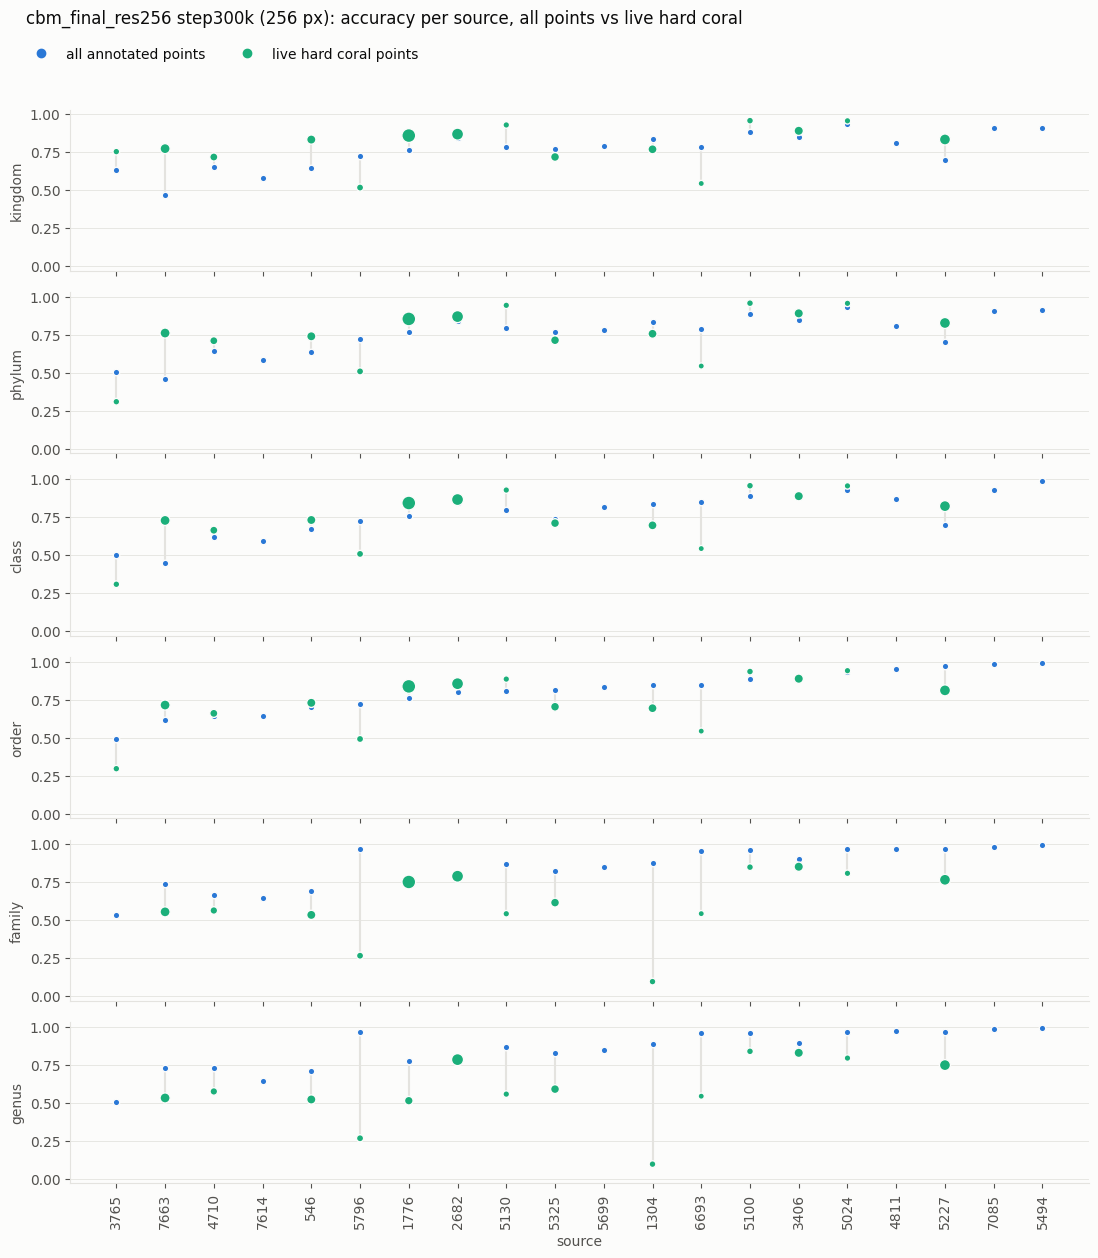

In [24]:
def plot_live_vs_all(name: str):
    t = tables[name].merge(live_tables[name], on=["source_id", "rank"], how="left")
    ranks = dumps[name].ranks
    fig, axes = plt.subplots(len(ranks), 1, figsize=(max(8, 0.45 * len(SOURCE_ORDER) + 2), 2.1 * len(ranks)), sharex=True)
    xpos = {s: i for i, s in enumerate(SOURCE_ORDER)}
    for ax, rank in zip(axes, ranks):
        x = t[t["rank"] == rank].copy(); x["x"] = x.source_id.map(xpos)
        a = x[x.n_points >= MIN_POINTS]; l = x[x.live_n >= MIN_LIVE]
        for _, r in l.iterrows():
            if r.n_points >= MIN_POINTS:
                ax.plot([r.x, r.x], [r.accuracy, r.live_accuracy], color=GRID, lw=1.5, zorder=1)
        ax.scatter(a.x, a.accuracy, s=22, color=COLOR, edgecolor=SURFACE, linewidth=1, zorder=3)
        ax.scatter(l.x, l.live_accuracy, s=10 + 1.5 * np.sqrt(l.live_n), color="#1baf7a", edgecolor=SURFACE, linewidth=1, zorder=3)
        ax.set_ylabel(rank); ax.set_ylim(-0.03, 1.03); ax.grid(axis="y", color=GRID, lw=0.6)
    axes[-1].set_xticks(range(len(SOURCE_ORDER)), SOURCE_ORDER if LABEL_SOURCES else range(1, len(SOURCE_ORDER) + 1), rotation=90)
    axes[-1].set_xlabel("source")
    handles = [Line2D([], [], marker="o", ls="", color=COLOR, label="all annotated points"),
               Line2D([], [], marker="o", ls="", color="#1baf7a", label="live hard coral points")]
    fig.legend(handles=handles, loc="upper left", ncol=2, frameon=False, bbox_to_anchor=(0.01, 0.975))
    fig.suptitle(f"{name}: accuracy per source, all points vs live hard coral", x=0.02, y=0.995, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.955))
    return fig

for name in dumps:
    plot_live_vs_all(name); plt.show()

### Live hard coral detection per source
Precision, recall and F1 of the binary live-hard-coral call on all points with determinable ground truth. Sources with
fewer than `MIN_LIVE` live hard coral points are left out.

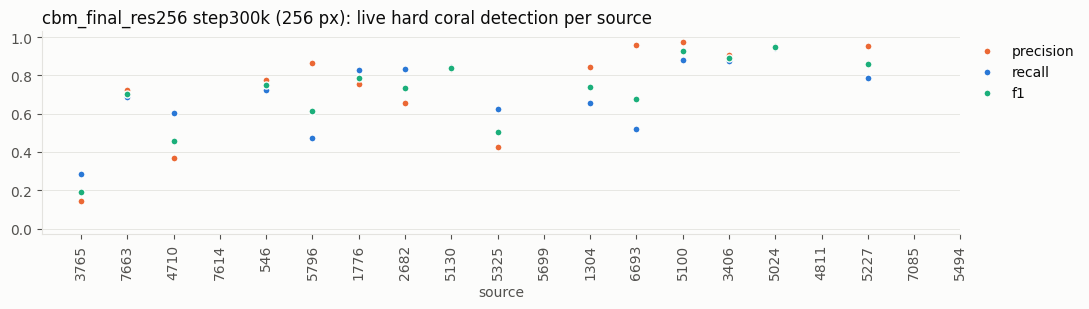

,tp,fp,fn,precision,recall,f1,n_live
source_id,,,,,,,
3765,23,136,58,0.145,0.284,0.192,81
7663,561,217,253,0.721,0.689,0.705,814
4710,158,270,104,0.369,0.603,0.458,262
546,381,110,144,0.776,0.726,0.750,525
5796,57,9,63,0.864,0.475,0.613,120
1776,2963,969,619,0.754,0.827,0.789,3582
2682,1582,838,321,0.654,0.831,0.732,1903
5130,59,12,11,0.831,0.843,0.837,70
5325,263,358,159,0.424,0.623,0.504,422


In [25]:
DET_COLORS = {"precision": "#eb6834", "recall": "#2a78d6", "f1": "#1baf7a"}
for name in dumps:
    t = live_det[name].reindex(SOURCE_ORDER)
    t = t[t.n_live >= MIN_LIVE]
    t_show = t
    fig, ax = plt.subplots(figsize=(max(8, 0.45 * len(SOURCE_ORDER) + 2), 3.2))
    xpos = {s: i for i, s in enumerate(SOURCE_ORDER)}
    for k, c in DET_COLORS.items():
        ax.scatter(t.index.map(xpos), t[k], s=26, color=c, edgecolor=SURFACE, linewidth=1, label=k, zorder=3)
    ax.set_xticks(range(len(SOURCE_ORDER)), SOURCE_ORDER if LABEL_SOURCES else range(1, len(SOURCE_ORDER) + 1), rotation=90)
    ax.set_ylim(-0.03, 1.03); ax.grid(axis="y", color=GRID, lw=0.6); ax.set_xlabel("source")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0)); ax.set_title(f"{name}: live hard coral detection per source", loc="left")
    fig.tight_layout(); plt.show()
    display(t_show.round(3))

### Interpretation (live hard coral; cbm_final_res256, 20 sources, seed 0)

10.3k of the points in these 20 sources are live hard coral.

**The taxonomy is easier at the top for coral than overall, and harder at the bottom.** Pooled accuracy on live hard
coral is 0.83 at kingdom, 0.80 at order, 0.72 at family and 0.67 at genus. At kingdom, 8 of the 15 sources with enough
live coral score *higher* on coral than on all their points, and 4 lower. The kingdom errors that dominate the earlier sections (algae, dead coral and
turf predicted `none`) are not live coral, so this subset avoids them. At family and genus it reverses: the all-points
numbers there include many easy `none` points (sand, turf), while live coral has to be named down to the family. The
mean over sources (0.61 family, 0.59 genus) sits below the pooled number, so small sources do worse.

**Most live-coral errors are "not coral", not the wrong coral.** In the sources with the largest gaps (1304, 5796, 6693)
nearly all family errors are `none`. *Acropora cervicornis* in 1304, *Porites lobata* in 5796 and 6693, and *Pavona*
and *Montipora* in 5796 are predicted as no taxon, not as another coral family. Confusions between coral families are
rare. This is the same "living → none" failure as at kingdom, here appearing lower in the hierarchy.

**Detection (precision 0.72, recall 0.78, F1 0.75 pooled) varies a lot by source, and the weak ones fail for
identifiable reasons:**
- **5325** (precision 0.42): `cred-octocoral` points predicted as live Scleractinia (268 of the false positives). This
  is the octocoral → hexacoral confusion from the class section. Its misses are mostly *Montipora capitata*.
- **4710** (precision 0.37): pavement, encrusting algae and Xeniidae soft coral called live hard coral. Its misses are
  massive *Porites* and generic "hard coral (massive)".
- **3765** (F1 0.19, only 81 live coral points): the temperate / fouling-community source. Bryozoans, algal turf and
  crustose algae are called coral, and generic `hard coral` points are missed.
- **5796, 6693**: high precision but recall about 0.5. These are under-calls of *Porites lobata* and similar massive
  coral, consistent with the `none` errors above.

The same views for all 144 sources and both final models are in `Model_Comparison_256_vs_768.ipynb`.
